In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
ls "/content/drive/MyDrive/base datos/Repositorio_UMSA_Informatica"

metadatos_informatica.csv  PDFs/


In [ ]:
r_base = "/content/drive/MyDrive/base datos/Repositorio_UMSA_Informatica"

In [ ]:
ruta_csv = os.path.join(r_base, 'metadatos_informatica.csv')

In [ ]:
ruta_csv

'/content/drive/MyDrive/base datos/Repositorio_UMSA_Informatica/metadatos_informatica.csv'

In [ ]:
df_metadatos = pd.read_csv(ruta_csv, encoding='utf-8')

In [ ]:
print(f"Filas (Proyectos): {df_metadatos.shape[0]}")

Filas (Proyectos): 79


In [ ]:
print(f"Columnas (Variables): {df_metadatos.shape[1]}\n")

Columnas (Variables): 9



In [ ]:
print(df_metadatos.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           79 non-null     int64 
 1   titulo       79 non-null     object
 2   autores      79 non-null     object
 3   tutores      79 non-null     object
 4   fecha        79 non-null     int64 
 5   materias     79 non-null     object
 6   resumen      78 non-null     object
 7   uri          79 non-null     object
 8   archivo_pdf  79 non-null     object
dtypes: int64(2), object(7)
memory usage: 5.7+ KB
None


In [ ]:
display(df_metadatos.head())

,id,titulo,autores,tutores,fecha,materias,resumen,uri,archivo_pdf
0,46610,Sistema de inventario para el control de produ...,"Yampara Ichuta, Ruddy Carlos","Felipez Andrade, Jhonny Roberto",2025,SISTEMA DE INVENTARIO; ARQUITECTURA CLIENTE-SE...,El presente proyecto de grado tiene como objet...,https://repositorio.umsa.bo/xmlui/handle/12345...,46610.pdf
1,46609,Sistema informático basado en microservicios p...,"Nina Gutierrez, Roman Olegario","Morales Ríos, Menfy",2025,COMUNICACIÓN EN MICROSERVICIOS; METODOLOGÍA ÁG...,Ante la limitada trazabilidad y control del ar...,https://repositorio.umsa.bo/xmlui/handle/12345...,46609.pdf
2,46608,Software de logística y gestión de buses para ...,"Ramos Escobar, Bladimir Wilson","Cuevas Quiroz, Franz",2025,METODOLOGÍA ÁGIL XP; SISTEMA DE CONTROL DE TRA...,El proyecto titulado “Software de logística y ...,https://repositorio.umsa.bo/xmlui/handle/12345...,46608.pdf
3,46587,Gestión de cotizaciones de servicios de softwa...,"Laime Mullisaca, Gladys Celia","Cuenca Sarzuri, Yohoni",2021,INGENIERÍA DE SOFTWARE; ESTIMACIÓN DE LÍNEAS D...,Las empresas con el pasar del tiempo hay recon...,https://repositorio.umsa.bo/xmlui/handle/12345...,46587.pdf
4,46577,Reconocimiento de marcas óptico para la detecc...,"Cori Tantani, Daynor","Cuevas Quiroz, Franz",2024,RECONOCIMIENTO ÓPTICO PARA CALIFICACIÓN; VISIÓ...,En la Unidad Educativa Boliviano Alemán 16 de ...,https://repositorio.umsa.bo/xmlui/handle/12345...,46577.pdf


In [ ]:
display(df_metadatos.describe(include='all'))

,id,titulo,autores,tutores,fecha,materias,resumen,uri,archivo_pdf
count,79.000000,79,79,79,79.000000,79,78,79,79
unique,NaN,77,77,42,NaN,78,77,79,79
top,NaN,Sistema de información para la asignación y co...,"Laura Torrez, Fernando","Valdez Alvarado, Aldo Ramiro",NaN,SISTEMAS DE INFORMACIÓN; GESTIÓN DE INFORMACIÓ...,El contar con un sistema de información es una...,https://repositorio.umsa.bo/xmlui/handle/12345...,46610.pdf
freq,NaN,2,2,14,NaN,2,2,1,1
mean,38871.962025,NaN,NaN,NaN,2021.202532,NaN,NaN,NaN,NaN
std,6209.766907,NaN,NaN,NaN,2.053014,NaN,NaN,NaN,NaN
min,27966.000000,NaN,NaN,NaN,2008.000000,NaN,NaN,NaN,NaN
25%,36619.500000,NaN,NaN,NaN,2020.000000,NaN,NaN,NaN,NaN
50%,36652.000000,NaN,NaN,NaN,2021.000000,NaN,NaN,NaN,NaN
75%,46515.000000,NaN,NaN,NaN,2022.000000,NaN,NaN,NaN,NaN


In [ ]:
print("--- 1. ANÁLISIS DE VALORES FALTANTES (NULOS) ---")
nulos = df_metadatos.isnull().sum()
porcentaje_nulos = (nulos / len(df_metadatos)) * 100
df_nulos = pd.DataFrame({'Total Nulos': nulos, 'Porcentaje (%)': porcentaje_nulos})
display(df_nulos[df_nulos['Total Nulos'] > 0].sort_values(by='Porcentaje (%)', ascending=False))

--- 1. ANÁLISIS DE VALORES FALTANTES (NULOS) ---


,Total Nulos,Porcentaje (%)
resumen,1,1.265823


In [ ]:
print("\n--- 2. TRATAMIENTO DE DATOS DUPLICADOS ---")
duplicados = df_metadatos.duplicated().sum()
print(f"Cantidad de filas duplicadas exactas: {duplicados}")


--- 2. TRATAMIENTO DE DATOS DUPLICADOS ---
Cantidad de filas duplicadas exactas: 0


In [ ]:
print("\n--- 3. DETECCIÓN INICIAL DE OUTLIERS (Ejemplo: Año) ---")
# Suponiendo que existe una columna de 'Año' o 'Año_Publicacion'
columnas_posibles = [col for col in df_metadatos.columns if 'año' in col.lower() or 'year' in col.lower()]
if columnas_posibles:
    col_año = columnas_posibles[0]
    print(f"Analizando posibles outliers en la columna: {col_año}")
    print(df_metadatos[col_año].describe())

    # Visualización con Boxplot
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df_metadatos[col_año])
    plt.title(f'Distribución y Detección de Outliers: {col_año}')
    plt.show()
else:
    print("No se encontró una columna relacionada con el año automáticamente.")


--- 3. DETECCIÓN INICIAL DE OUTLIERS (Ejemplo: Año) ---
No se encontró una columna relacionada con el año automáticamente.


In [ ]:
ruta_pdfs = os.path.join(r_base, 'PDFs')

In [ ]:
archivos_pdf = glob.glob(os.path.join(ruta_pdfs, '*.pdf'))

In [ ]:
print(f"--- VERIFICACIÓN DE ARCHIVOS FÍSICOS ---")
print(f"Total de archivos PDF encontrados en la carpeta: {len(archivos_pdf)}")
print(f"Total de registros en el CSV de metadatos: {len(df_metadatos)}")


--- VERIFICACIÓN DE ARCHIVOS FÍSICOS ---
Total de archivos PDF encontrados en la carpeta: 79
Total de registros en el CSV de metadatos: 79


In [ ]:
if len(archivos_pdf) != len(df_metadatos):
        print("ALERTA: Existe una discrepancia entre la cantidad de PDFs y los registros del CSV.")
        print("Esto puede deberse a PDFs sin metadatos o metadatos sin PDFs.")

In [ ]:
tamanos = [os.path.getsize(f) / (1024 * 1024) for f in archivos_pdf] # Tamaño en MB
print(f"\nTamaño promedio de los PDFs: {np.mean(tamanos):.2f} MB")
print(f"Tamaño máximo: {np.max(tamanos):.2f} MB")
print(f"Tamaño mínimo: {np.min(tamanos):.2f} MB")


Tamaño promedio de los PDFs: 4.52 MB
Tamaño máximo: 19.57 MB
Tamaño mínimo: 0.95 MB


In [ ]:
archivos_pequenos = [f for f in archivos_pdf if os.path.getsize(f) < 10000]
if archivos_pequenos:
        print(f"\nALERTA: Se encontraron {len(archivos_pequenos)} archivos menores a 10KB (posibles errores):")
        for f in archivos_pequenos:
            print(f" - {os.path.basename(f)}")
else:
    print("No se encontraron archivos menores a 10KB.")

No se encontraron archivos menores a 10KB.


In [ ]:
columnas_categoricas = df_metadatos.select_dtypes(include=['object']).columns

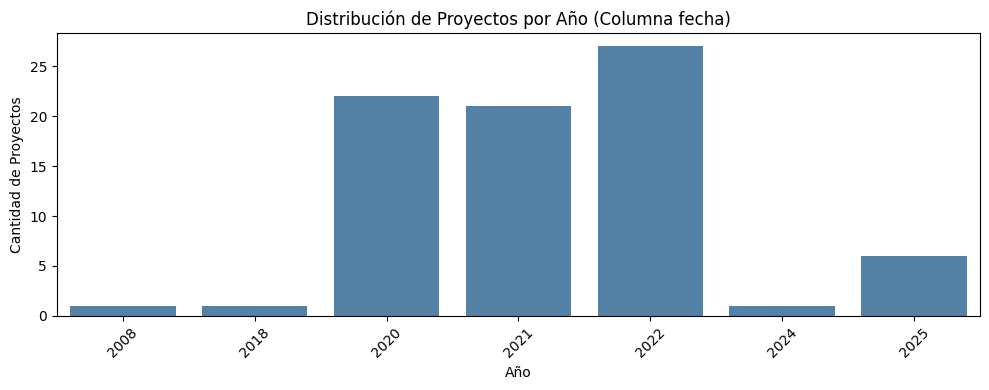

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Gráfico específico para la columna 'fecha' (Años)
plt.figure(figsize=(10, 4))
sns.countplot(data=df_metadatos, x='fecha', color='steelblue')
plt.title('Distribución de Proyectos por Año (Columna fecha)')
plt.xlabel('Año')
plt.ylabel('Cantidad de Proyectos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_5492/802511655.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_tutores.values, y=top_tutores.index, palette='viridis')


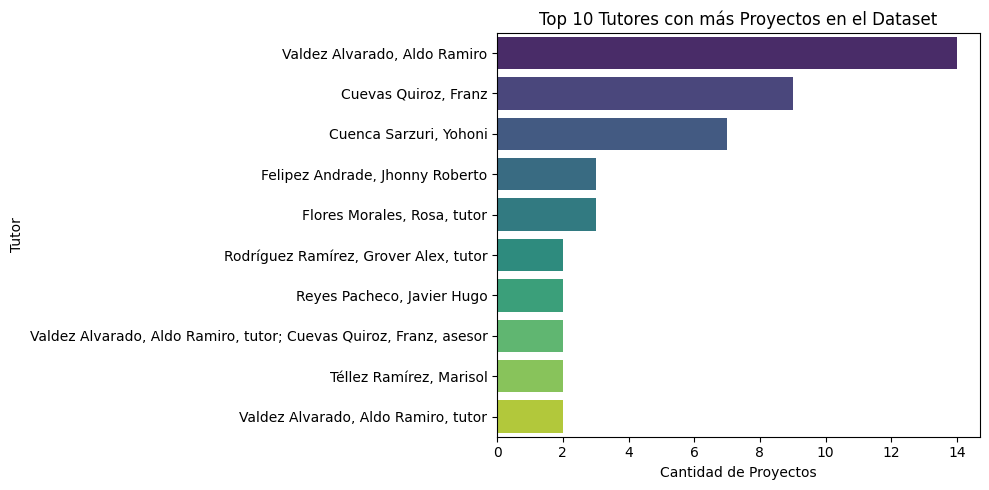

In [ ]:
# 2. Gráfico para identificar a los Tutores con más proyectos dirigidos (Top 10)
plt.figure(figsize=(10, 5))
top_tutores = df_metadatos['tutores'].value_counts().head(10)
sns.barplot(x=top_tutores.values, y=top_tutores.index, palette='viridis')
plt.title('Top 10 Tutores con más Proyectos en el Dataset')
plt.xlabel('Cantidad de Proyectos')
plt.ylabel('Tutor')
plt.tight_layout()
plt.show()

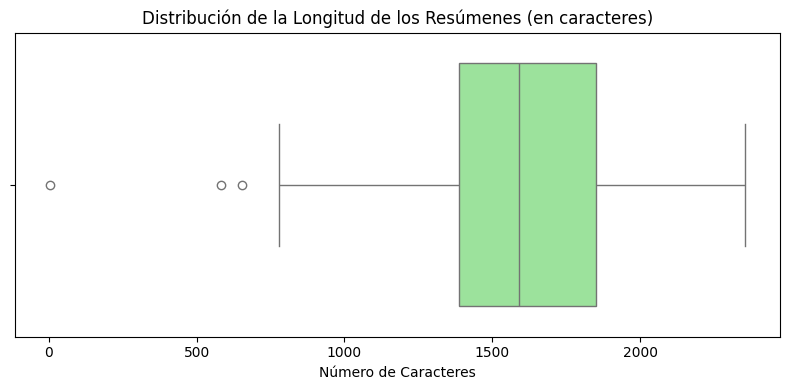

Análisis visual completado. Se observa la distribución temporal, de tutores y de longitud de resúmenes.


In [ ]:
df_metadatos['longitud_resumen'] = df_metadatos['resumen'].astype(str).apply(len)

plt.figure(figsize=(8, 4))
sns.boxplot(x=df_metadatos['longitud_resumen'], color='lightgreen')
plt.title('Distribución de la Longitud de los Resúmenes (en caracteres)')
plt.xlabel('Número de Caracteres')
plt.tight_layout()
plt.show()

print("Análisis visual completado. Se observa la distribución temporal, de tutores y de longitud de resúmenes.")

In [ ]:
!pip install pypdf

In [ ]:
import os
from pypdf import PdfReader
import pandas as pd

# Ruta donde están los PDFs
ruta_pdfs = os.path.join(r_base, 'PDFs')

# Función para extraer texto de un PDF
def extraer_texto_pdf(ruta_archivo):
    try:
        reader = PdfReader(ruta_archivo)
        texto_completo = ""
        for pagina in reader.pages:
            texto_pagina = pagina.extract_text()
            if texto_pagina:
                texto_completo += texto_pagina + "\n"
        return texto_completo
    except Exception as e:
        return f"ERROR: {str(e)}"

# Prueba de extracción con el PRIMER documento del dataset
# Tomamos el nombre del archivo de la primera fila del CSV
primer_pdf = df_metadatos['archivo_pdf'].iloc[0]
ruta_primer_pdf = os.path.join(ruta_pdfs, primer_pdf)

print(f"--- PROBANDO EXTRACCIÓN CON EL ARCHIVO: {primer_pdf} ---")
texto_prueba = extraer_texto_pdf(ruta_primer_pdf)

# Mostrar los primeros 1000 caracteres extraídos
if "ERROR" not in texto_prueba:
    print(f"Extracción exitosa. Longitud del texto: {len(texto_prueba)} caracteres.")
    print("\n--- PRIMEROS 1000 CARACTERES EXTRAÍDOS ---")
    print(texto_prueba[:1000])
else:
    print(texto_prueba)

--- PROBANDO EXTRACCIÓN CON EL ARCHIVO: 46610.pdf ---
Extracción exitosa. Longitud del texto: 263546 caracteres.

--- PRIMEROS 1000 CARACTERES EXTRAÍDOS ---
1 
UNIVERSIDAD MAYOR DE SAN ANDRÉS 
FACULTAD DE CIENCIAS PURAS Y NATURALES 
CARRERA DE INFORMÁTICA 
 
PROYECTO DE GRADO 
SISTEMA DE INVENTARIO PARA EL CONTROL DE 
PRODUCTOS  
CASO: SESHIRYA IMPORT EXPORT S.R.L. 
 
PARA OPTAR AL TÍTULO DE LICENCIATURA EN INFORMÁTICA 
MENCIÓN: INGENIERÍA DE SISTEMAS INFORMÁTICOS 
 
POSTULANTE: RUDDY CARLOS YAMPARA ICHUTA 
TUTOR: LIC. JHONNY ROBERTO FELIPEZ ANDRADE 
 
LA PAZ – BOLIVIA 
2025 
i1 

 
HOJA DE CALIFICACIONES 
UNIVERSIDAD MAYOR DE SAN ANDRÉS 
FACULTAD DE CIENCIAS PURAS Y NATURALES 
CARRERA DE INFORMÁTICA 
Proyecto de grado: 
SISTEMA DE INVENTARIO PARA EL CONTROL DE PRODUCTOS  
CASO: SESHIRYA IMPORT EXPORT S.R.L. 
 
Presentado por: Ruddy Carlos Yampra Ichuta 
Para optar el grado Académico de Licenciado en Informática 
Mención Ingeniería de Sistemas Informáticos 
Nota Numeral:  95 
Nota Lite

--- TOP 5 TUTORES DESPUÉS DE LA LIMPIEZA ---
tutores_limpios
Valdez Alvarado, Aldo Ramiro       16
Cuevas Quiroz, Franz                9
Cuenca Sarzuri, Yohoni              7
Flores Morales, Rosa                4
Felipez Andrade, Jhonny Roberto     3
Name: count, dtype: int64


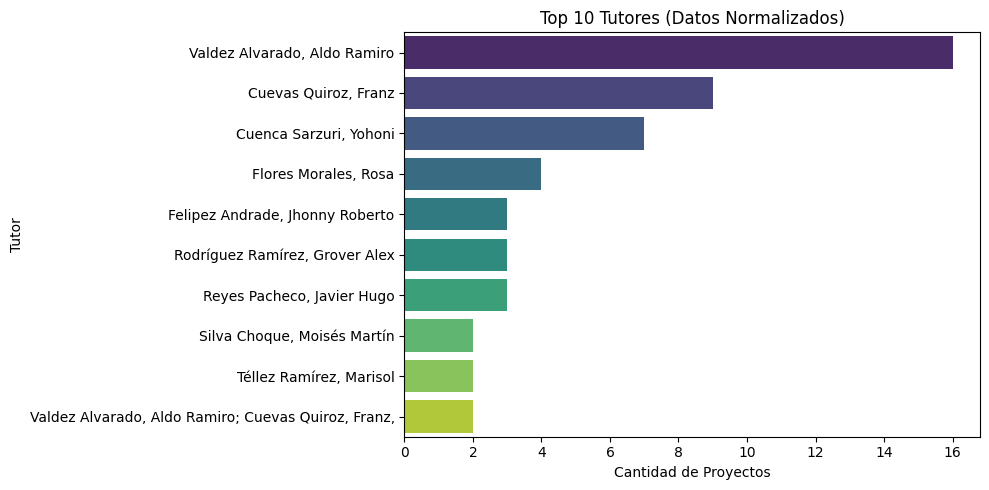

In [ ]:
# Bloque 7: Normalización de la columna de tutores
import pandas as pd

# Limpiar sufijos como ", tutor", ", asesora", etc., usando expresiones regulares
df_metadatos['tutores_limpios'] = df_metadatos['tutores'].str.replace(
    r',\s*tutor|\s*tutor|\s*asesor|\s*asesora', '', regex=True, case=False
).str.strip()

# Verificar el cambio
print("--- TOP 5 TUTORES DESPUÉS DE LA LIMPIEZA ---")
print(df_metadatos['tutores_limpios'].value_counts().head(5))

# Gráfico corregido sin warnings
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
top_tutores_limpios = df_metadatos['tutores_limpios'].value_counts().head(10)
sns.barplot(x=top_tutores_limpios.values, y=top_tutores_limpios.index, hue=top_tutores_limpios.index, palette='viridis', legend=False)
plt.title('Top 10 Tutores (Datos Normalizados)')
plt.xlabel('Cantidad de Proyectos')
plt.ylabel('Tutor')
plt.tight_layout()
plt.show()

In [ ]:
# Bloque 8: Extracción y segmentación de todos los PDFs
import os
import re
from pypdf import PdfReader
from tqdm import tqdm # Para ver la barra de progreso (instalar con !pip install tqdm)

ruta_pdfs = os.path.join(r_base, 'PDFs')
textos_segmentados = []

print("Iniciando extracción masiva de PDFs...")

for index, row in tqdm(df_metadatos.iterrows(), total=len(df_metadatos)):
    nombre_archivo = row['archivo_pdf']
    ruta_completa = os.path.join(ruta_pdfs, nombre_archivo)

    try:
        # Extraer texto
        reader = PdfReader(ruta_completa)
        texto_completo = ""
        for pagina in reader.pages:
            texto_completo += pagina.extract_text() + "\n"

        # --- SEGMENTACIÓN HEURÍSTICA ---
        # Buscar patrones comunes en tesis de la UMSA (usando Regex)
        # Nota: Estos patrones pueden requerir ajustes finos tras revisar más documentos.

        # Intentar extraer Introducción (desde "INTRODUCCIÓN" hasta "CAPÍTULO II" o "MARCO TEÓRICO")
        intro_match = re.search(r'(INTRODUCCIÓN|CAPÍTULO I.*?INTRODUCCIÓN)(.*?)(?=CAPÍTULO II|MARCO TEÓRICO|MARCO REFERENCIAL)', texto_completo, re.IGNORECASE | re.DOTALL)
        introduccion = intro_match.group(2)[:5000] if intro_match else "" # Limitamos a 5000 caracteres para no saturar memoria

        # Intentar extraer Conclusiones (desde "CONCLUSIONES" hasta el final o "RECOMENDACIONES")
        conclusion_match = re.search(r'(CONCLUSIONES)(.*?)(?=RECOMENDACIONES|BIBLIOGRAFÍA|ANEXOS|$)', texto_completo, re.IGNORECASE | re.DOTALL)
        conclusiones = conclusion_match.group(2)[:5000] if conclusion_match else ""

        # Guardar resultados
        textos_segmentados.append({
            'id': row['id'],
            'archivo_pdf': nombre_archivo,
            'texto_completo_len': len(texto_completo),
            'tiene_introduccion': len(introduccion) > 100, # True si encontró texto
            'introduccion_texto': introduccion,
            'tiene_conclusiones': len(conclusiones) > 100,
            'conclusiones_texto': conclusiones
        })

    except Exception as e:
        print(f"Error procesando {nombre_archivo}: {e}")

# Crear un nuevo DataFrame con los textos extraídos
df_textos = pd.DataFrame(textos_segmentados)

# Guardar el progreso para no tener que volver a leer los PDFs
ruta_guardado = os.path.join(r_base, 'dataset_textos_extraidos.csv')
df_textos.to_csv(ruta_guardado, index=False, encoding='utf-8')

print(f"\nExtracción completada. Se procesaron {len(df_textos)} documentos.")
print(f"Archivo guardado en: {ruta_guardado}")
print("\n--- MUESTRA DE LOS DATOS EXTRAÍDOS ---")
display(df_textos[['archivo_pdf', 'texto_completo_len', 'tiene_introduccion', 'tiene_conclusiones']].head())

Iniciando extracción masiva de PDFs...


100%|██████████| 79/79 [05:11<00:00,  3.94s/it]


Extracción completada. Se procesaron 79 documentos.
Archivo guardado en: /content/drive/MyDrive/base datos/Repositorio_UMSA_Informatica/dataset_textos_extraidos.csv

--- MUESTRA DE LOS DATOS EXTRAÍDOS ---


,archivo_pdf,texto_completo_len,tiene_introduccion,tiene_conclusiones
0,46610.pdf,263546,True,False
1,46609.pdf,219604,True,False
2,46608.pdf,189060,True,False
3,46587.pdf,104512,True,False
4,46577.pdf,171706,True,False


In [ ]:
# Bloque de Depuración: Buscar cómo está escrita la sección de conclusiones
import re

# Tomamos el primer PDF de la lista
ruta_primer_pdf = os.path.join(ruta_pdfs, df_metadatos['archivo_pdf'].iloc[0])
texto_debug = extraer_texto_pdf(ruta_primer_pdf)

# Buscar la palabra "conclusion" (ignorando mayúsculas/minúsculas)
matches = [m.start() for m in re.finditer(r'(?i)conclusion', texto_debug)]

if matches:
    print(f"Se encontraron {len(matches)} coincidencias para 'conclusión'.")
    # Imprimir los 300 caracteres antes y 500 después de la primera coincidencia
    idx = matches[0]
    print("\n--- CONTEXTO ALREDEDOR DE LA PRIMERA COINCIDENCIA ---")
    print(texto_debug[max(0, idx-100): idx+500])
else:
    print("No se encontró la palabra 'conclusión' en absoluto.")

Se encontraron 11 coincidencias para 'conclusión'.

--- CONTEXTO ALREDEDOR DE LA PRIMERA COINCIDENCIA ---
.............................................................................................. 187 
CONCLUSIONES Y RECOMENDACIONES...................................................................... 187 
7.1 Conclusiones.........................................................................................................................187 
7.1.1 Conclusiones de Objetivos Específicos....................................................................... 187 
7.1.2 Conclusiones de Objetivo General...............................................................................188 
7.1.3 Conc


In [ ]:
# Bloque 8: Extracción y segmentación definitiva (Ignorando el Índice)
import os
import re
from pypdf import PdfReader
from tqdm import tqdm
import pandas as pd

ruta_pdfs = os.path.join(r_base, 'PDFs')
textos_segmentados_v3 = []

print("Iniciando extracción masiva definitiva...")

for index, row in tqdm(df_metadatos.iterrows(), total=len(df_metadatos)):
    nombre_archivo = row['archivo_pdf']
    ruta_completa = os.path.join(ruta_pdfs, nombre_archivo)

    try:
        reader = PdfReader(ruta_completa)
        texto_completo = ""
        for pagina in reader.pages:
            texto_pagina = pagina.extract_text()
            if texto_pagina:
                texto_completo += texto_pagina + "\n"

        # --- LÓGICA DE EXTRACCIÓN MEJORADA ---
        # Encontrar todas las apariciones de "conclusión" o "conclusiones"
        coincidencias = list(re.finditer(r'(?i)\b(CONCLUSIONES|CONCLUSIÓN)\b', texto_completo))

        conclusiones_texto = ""
        introduccion_texto = ""

        # 1. Extraer Conclusiones (Evitando el índice)
        for match in coincidencias:
            idx_inicio = match.start()
            # Extraer un bloque de texto desde la coincidencia
            bloque_texto = texto_completo[idx_inicio : idx_inicio + 10000]

            # Heurística: Si los primeros 500 caracteres tienen más de 20 puntos, es el índice.
            primeros_500 = bloque_texto[:500]
            if primeros_500.count('.') > 20:
                continue # Ignorar, es el índice, buscar la siguiente aparición

            # Si pasamos el filtro, es el cuerpo real. Extraer hasta Bibliografía o Anexos
            match_fin = re.search(r'(?i)(BIBLIOGRAFIA|BIBLIOGRAFÍA|REFERENCIAS|ANEXOS)', bloque_texto)
            if match_fin:
                conclusiones_texto = bloque_texto[:match_fin.start()].strip()
            else:
                conclusiones_texto = bloque_texto.strip()

            # Limpiar saltos de línea excesivos y números de página sueltos
            conclusiones_texto = re.sub(r'\n\s*\d+\s*\n', '\n', conclusiones_texto)
            conclusiones_texto = re.sub(r'\n+', '\n', conclusiones_texto).strip()
            break # Ya encontramos la sección real, dejamos de buscar

        # 2. Extraer Introducción (Lógica similar)
        match_intro = re.search(r'(?i)\b(INTRODUCCIÓN|INTRODUCCION)\b', texto_completo)
        if match_intro:
            # Tomar los primeros 5000 caracteres después de "Introducción"
            bloque_intro = texto_completo[match_intro.start() : match_intro.start() + 6000]
            # Intentar cortar en el siguiente capítulo
            match_fin_intro = re.search(r'(?i)(CAPÍTULO\s*II|MARCO\s*TEÓRICO|MARCO\s*REFERENCIAL)', bloque_intro)
            if match_fin_intro:
                introduccion_texto = bloque_intro[:match_fin_intro.start()].strip()
            else:
                introduccion_texto = bloque_intro.strip()
            introduccion_texto = re.sub(r'\n\s*\d+\s*\n', '\n', introduccion_texto)

        # Guardar resultados
        textos_segmentados_v3.append({
            'id': row['id'],
            'archivo_pdf': nombre_archivo,
            'texto_completo_len': len(texto_completo),
            'tiene_introduccion': len(introduccion_texto) > 200,
            'tiene_conclusiones': len(conclusiones_texto) > 200,
            'conclusiones_texto': conclusiones_texto[:5000] # Guardar solo los primeros 5000 para no saturar
        })

    except Exception as e:
        print(f"Error en {nombre_archivo}: {e}")

# Crear DataFrame
df_segmentado_v3 = pd.DataFrame(textos_segmentados_v3)

# Mostrar resultados
print("--- RESULTADOS DE LA SEGMENTACIÓN V3 ---")
display(df_segmentado_v3[['archivo_pdf', 'tiene_introduccion', 'tiene_conclusiones']].head())

# Calcular porcentajes de éxito
exito_intro = df_segmentado_v3['tiene_introduccion'].mean() * 100
exito_conclu = df_segmentado_v3['tiene_conclusiones'].mean() * 100
print(f"\nPorcentaje de documentos con Introducción detectada: {exito_intro:.2f}%")
print(f"Porcentaje de documentos con Conclusiones detectadas: {exito_conclu:.2f}%")

# Guardar el dataset final de esta fase
ruta_guardado_v3 = os.path.join(r_base, 'dataset_segmentado_v3.csv')
df_segmentado_v3.to_csv(ruta_guardado_v3, index=False, encoding='utf-8')
print(f"\nDataset guardado exitosamente en: {ruta_guardado_v3}")

Iniciando extracción masiva definitiva...


100%|██████████| 79/79 [04:58<00:00,  3.78s/it]

--- RESULTADOS DE LA SEGMENTACIÓN V3 ---


,archivo_pdf,tiene_introduccion,tiene_conclusiones
0,46610.pdf,True,True
1,46609.pdf,True,True
2,46608.pdf,True,True
3,46587.pdf,True,True
4,46577.pdf,True,True



Porcentaje de documentos con Introducción detectada: 98.73%
Porcentaje de documentos con Conclusiones detectadas: 92.41%

Dataset guardado exitosamente en: /content/drive/MyDrive/base datos/Repositorio_UMSA_Informatica/dataset_segmentado_v3.csv


In [ ]:
# Bloque 9 CORREGIDO: Preprocesamiento de Texto (NLP)
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import SnowballStemmer
import string

# --- SOLUCIÓN AL ERROR: Descargar el recurso faltante 'punkt_tab' ---
nltk.download('punkt')
nltk.download('punkt_tab')  # <-- Línea clave para resolver el LookupError
nltk.download('stopwords')

# Cargar el dataset generado en el paso anterior
ruta_dataset = os.path.join(r_base, 'dataset_segmentado_v3.csv')
df_textos = pd.read_csv(ruta_dataset)

# Definir herramientas de NLP en español
stop_words = set(stopwords.words('spanish'))
stemmer = SnowballStemmer('spanish')

def limpiar_texto(texto):
    if pd.isna(texto) or not isinstance(texto, str):
        return ""

    # 1. Convertir a minúsculas
    texto = texto.lower()

    # 2. Eliminar números de página sueltos y saltos de línea excesivos
    texto = re.sub(r'\n+', ' ', texto)
    texto = re.sub(r'\b\d+\b', '', texto)

    # 3. Eliminar signos de puntuación
    texto = texto.translate(str.maketrans('', '', string.punctuation + '¡¿«»'))

    # 4. Tokenización (dividir en palabras)
    # Se especifica el idioma español para que use el modelo correcto
    tokens = word_tokenize(texto, language='spanish')

    # 5. Eliminar stopwords y aplicar stemming (reducción a la raíz de la palabra)
    tokens_limpios = [stemmer.stem(word) for word in tokens if word not in stop_words and len(word) > 2]

    return " ".join(tokens_limpios)

print("Aplicando limpieza NLP a las conclusiones...")
# Aplicar la función solo a los documentos donde se encontraron conclusiones
df_textos['conclusiones_limpias'] = df_textos['conclusiones_texto'].apply(limpiar_texto)

# Mostrar un ejemplo del antes y después
print("\n--- EJEMPLO DE TEXTO ORIGINAL (primeros 300 caracteres) ---")
print(str(df_textos['conclusiones_texto'].iloc[0])[:300])

print("\n--- EJEMPLO DE TEXTO LIMPIO (primeros 300 caracteres) ---")
print(str(df_textos['conclusiones_limpias'].iloc[0])[:300])

# Guardar el avance
ruta_guardado_nlp = os.path.join(r_base, 'dataset_nlp_limpio.csv')
df_textos.to_csv(ruta_guardado_nlp, index=False, encoding='utf-8')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Aplicando limpieza NLP a las conclusiones...

--- EJEMPLO DE TEXTO ORIGINAL (primeros 300 caracteres) ---
conclusión, proporciona un marco 
sólido para identificar las causas del problema, proponer soluciones viables y validar su 
eficacia en un entorno real. 
Esta metodología no solo asegura un proceso lógico y ordenado, sino que también 
facilita la integración de herramientas tecnológicas y procedimi

--- EJEMPLO DE TEXTO LIMPIO (primeros 300 caracteres) ---
conclusion proporcion marc sol identific caus problem propon solucion viabl valid eficaci entorn real metodolog sol asegur proces logic orden sin facilit integr herramient tecnolog proced orient mejor continu combin enfoqu etap especif desarroll sistem planif estrateg analisis detall requer diseñ es


Total de documentos válidos para análisis de similitud: 73
Dimensiones de la matriz TF-IDF: (73, 1500)
(Filas = Documentos, Columnas = Palabras relevantes)



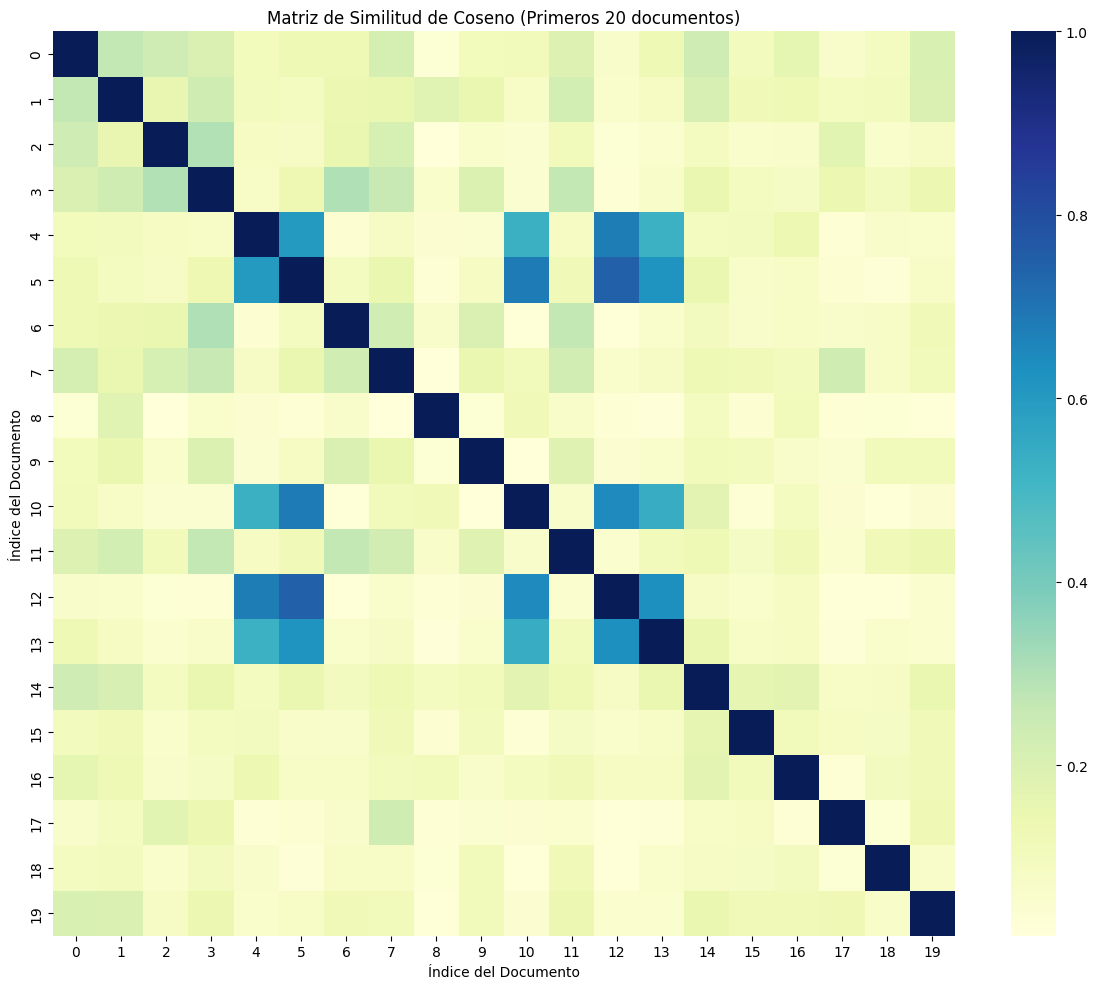

--- PAR DE DOCUMENTOS CON MAYOR SIMILITUD ---
Documento 1: 46514.pdf
Documento 2: 36615.pdf
Porcentaje de similitud: 100.00%

--- Fragmento de las conclusiones de 46514.pdf ---
conclusión de sistema, existen tres tipos de riesgo. 
• Riesgo del proyecto, que afecta al calendario o al rendimiento del 
sistema que se está desarrollando. 
• Riesgo del producto, afecta a la calidad o al rendimiento del sistema que 
se está desarrollando. 
• Riesgo de negocio, afectan a la organización que desarrolla o suministra 
el sistema. 
Los riesgos que se encuentran para el desarrollo d...

--- Fragmento de las conclusiones de 36615.pdf ---
conclusión de sistema, existen tres tipos de riesgo. 
• Riesgo del proyecto, que afecta al calendario o al rendimiento del 
sistema que se está desarrollando. 
• Riesgo del producto, afecta a la calidad o al rendimiento del sistema que 
se está desarrollando. 
• Riesgo de negocio, afectan a la organización que desarrolla o suministra 
el sistema. 
Los riesgos que s

In [ ]:
# Bloque 10: Vectorización TF-IDF y Matriz de Similitud
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Cargar el dataset que acabamos de limpiar en el Bloque 9
ruta_dataset_nlp = os.path.join(r_base, 'dataset_nlp_limpio.csv')
df_textos = pd.read_csv(ruta_dataset_nlp)

# 2. Filtrar solo los documentos que tienen conclusiones válidas y texto limpio
# Eliminamos posibles valores nulos (NaN) en la columna de texto limpio
df_validos = df_textos[df_textos['tiene_conclusiones'] == True].dropna(subset=['conclusiones_limpias']).reset_index(drop=True)

print(f"Total de documentos válidos para análisis de similitud: {len(df_validos)}")

# 3. Vectorización TF-IDF
# max_features=1500 limita el vocabulario a las 1500 palabras más importantes para no saturar la memoria
# min_df=2 ignora palabras que solo aparecen en 1 solo documento (ruido)
vectorizer = TfidfVectorizer(max_features=1500, min_df=2)
matriz_tfidf = vectorizer.fit_transform(df_validos['conclusiones_limpias'])

print(f"Dimensiones de la matriz TF-IDF: {matriz_tfidf.shape}")
print("(Filas = Documentos, Columnas = Palabras relevantes)\n")

# 4. Cálculo de Similitud de Coseno
# Esto compara cada documento contra todos los demás
matriz_similitud = cosine_similarity(matriz_tfidf)

# 5. Visualización: Mapa de Calor (Heatmap) de los primeros 20 documentos
plt.figure(figsize=(12, 10))
# Mostramos solo los primeros 20 para que el gráfico sea legible
sns.heatmap(matriz_similitud[:20, :20], cmap='YlGnBu', annot=False, cbar=True)
plt.title('Matriz de Similitud de Coseno (Primeros 20 documentos)')
plt.xlabel('Índice del Documento')
plt.ylabel('Índice del Documento')
plt.tight_layout()
plt.show()

# 6. Encontrar el par de documentos MÁS similares (excluyendo la comparación consigo mismo)
# Rellenamos la diagonal principal con -1 para ignorar la similitud de un documento consigo mismo (que siempre es 1)
np.fill_diagonal(matriz_similitud, -1)

# Obtener los índices del valor máximo en la matriz
indices_max = np.unravel_index(np.argmax(matriz_similitud, axis=None), matriz_similitud.shape)
doc1_idx, doc2_idx = indices_max
similitud_max = matriz_similitud[doc1_idx, doc2_idx]

print("="*50)
print("--- PAR DE DOCUMENTOS CON MAYOR SIMILITUD ---")
print("="*50)
print(f"Documento 1: {df_validos['archivo_pdf'].iloc[doc1_idx]}")
print(f"Documento 2: {df_validos['archivo_pdf'].iloc[doc2_idx]}")
print(f"Porcentaje de similitud: {similitud_max * 100:.2f}%\n")

# 7. Mostrar un fragmento de las conclusiones de ambos documentos para verificar la similitud lógica
print(f"--- Fragmento de las conclusiones de {df_validos['archivo_pdf'].iloc[doc1_idx]} ---")
print(str(df_validos['conclusiones_texto'].iloc[doc1_idx])[:400] + "...\n")

print(f"--- Fragmento de las conclusiones de {df_validos['archivo_pdf'].iloc[doc2_idx]} ---")
print(str(df_validos['conclusiones_texto'].iloc[doc2_idx])[:400] + "...")

In [ ]:
# Bloque 11: Refinamiento del Dataset (Eliminación de ruido y falsos positivos)
import pandas as pd
import os

# Cargar el dataset
ruta_dataset = os.path.join(r_base, 'dataset_nlp_limpio.csv')
df_textos = pd.read_csv(ruta_dataset)

# 1. Identificar el texto problemático (el fragmento de los 3 tipos de riesgo)
# Buscamos las palabras clave de ese fragmento genérico
texto_generico = "riesgo proyecto producto negocio"

# Creamos una columna para marcar estos textos
df_textos['es_texto_generico'] = df_textos['conclusiones_limpias'].apply(
    lambda x: True if isinstance(x, str) and texto_generico in x else False
)

# Ver cuántos documentos tienen este problema
print(f"Documentos con extracción genérica (ruido): {df_textos['es_texto_generico'].sum()}")

# 2. Filtrar el dataset para quedarnos solo con los textos válidos y únicos
df_validos_limpios = df_textos[
    (df_textos['tiene_conclusiones'] == True) &
    (df_textos['es_texto_generico'] == False) &
    (df_textos['conclusiones_limpias'].notna())
].reset_index(drop=True)

print(f"Total de documentos válidos después de limpiar el ruido: {len(df_validos_limpios)}")

# 3. Volver a calcular la matriz de similitud con los datos limpios
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

vectorizer = TfidfVectorizer(max_features=1500, min_df=2)
matriz_tfidf = vectorizer.fit_transform(df_validos_limpios['conclusiones_limpias'])
matriz_similitud = cosine_similarity(matriz_tfidf)

# Buscar el nuevo par más similar
np.fill_diagonal(matriz_similitud, -1)
indices_max = np.unravel_index(np.argmax(matriz_similitud, axis=None), matriz_similitud.shape)
doc1_idx, doc2_idx = indices_max
similitud_max = matriz_similitud[doc1_idx, doc2_idx]

print("\n" + "="*50)
print("--- NUEVO PAR MÁS SIMILAR (DATOS REFINADOS) ---")
print("="*50)
print(f"Documento 1: {df_validos_limpios['archivo_pdf'].iloc[doc1_idx]}")
print(f"Documento 2: {df_validos_limpios['archivo_pdf'].iloc[doc2_idx]}")
print(f"Porcentaje de similitud: {similitud_max * 100:.2f}%\n")

# Guardar el dataset final para la fase de modelado
ruta_dataset_final = os.path.join(r_base, 'dataset_final_para_modelado.csv')
df_validos_limpios.to_csv(ruta_dataset_final, index=False, encoding='utf-8')
print(f"Dataset final guardado en: {ruta_dataset_final}")

Documentos con extracción genérica (ruido): 0
Total de documentos válidos después de limpiar el ruido: 73

--- NUEVO PAR MÁS SIMILAR (DATOS REFINADOS) ---
Documento 1: 46514.pdf
Documento 2: 36615.pdf
Porcentaje de similitud: 100.00%

Dataset final guardado en: /content/drive/MyDrive/base datos/Repositorio_UMSA_Informatica/dataset_final_para_modelado.csv


In [ ]:
# Bloque 12: Re-extracción Definitiva y Robusta (Solución al problema del 100%)
import os
import re
from pypdf import PdfReader
from tqdm import tqdm
import pandas as pd

ruta_pdfs = os.path.join(r_base, 'PDFs')
textos_corregidos_v4 = []

print("Iniciando extracción posicional (buscando secciones al final del documento)...")

for index, row in tqdm(df_metadatos.iterrows(), total=len(df_metadatos)):
    nombre_archivo = row['archivo_pdf']
    ruta_completa = os.path.join(ruta_pdfs, nombre_archivo)

    try:
        reader = PdfReader(ruta_completa)
        texto_completo = ""
        for pagina in reader.pages:
            texto_pagina = pagina.extract_text()
            if texto_pagina:
                texto_completo += texto_pagina + "\n"

        # --- NUEVA LÓGICA DE EXTRACCIÓN POSICIONAL ---
        # Buscar todas las apariciones de la palabra (en mayúsculas o título)
        patron = r'(?i)\b(CONCLUSIONES|CONCLUSIÓN)\b'
        coincidencias = list(re.finditer(patron, texto_completo))

        conclusiones_texto = ""

        if coincidencias:
            # En lugar de tomar la primera, tomamos la ÚLTIMA aparición en el documento.
            # (Esto evita capturar índices o definiciones en el marco teórico).
            ultima_coincidencia = coincidencias[-1]
            idx_inicio = ultima_coincidencia.start()

            # Extraer un bloque de 15,000 caracteres desde la última coincidencia
            bloque_texto = texto_completo[idx_inicio : idx_inicio + 15000]

            # Intentar cortar si encontramos la bibliografía o anexos
            match_fin = re.search(r'(?i)(BIBLIOGRAFIA|BIBLIOGRAFÍA|REFERENCIAS|ANEXOS)', bloque_texto)
            if match_fin:
                conclusiones_texto = bloque_texto[:match_fin.start()].strip()
            else:
                conclusiones_texto = bloque_texto.strip()

            # Limpiar saltos de línea y números de página
            conclusiones_texto = re.sub(r'\n\s*\d+\s*\n', '\n', conclusiones_texto)

        # Guardar resultados
        textos_corregidos_v4.append({
            'id': row['id'],
            'archivo_pdf': nombre_archivo,
            'texto_completo_len': len(texto_completo),
            'tiene_conclusiones': len(conclusiones_texto) > 300, # Validar que tenga contenido real
            'conclusiones_texto': conclusiones_texto[:5000] # Guardar máximo 5000 para memoria
        })

    except Exception as e:
        pass # Ignorar errores

# Crear DataFrame
df_v4 = pd.DataFrame(textos_corregidos_v4)
print(f"\nDocumentos con conclusiones válidas detectadas: {df_v4['tiene_conclusiones'].sum()} de {len(df_v4)}")

# --- LIMPIEZA NLP (Aplicando el Bloque 9 directamente) ---
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
import string
from nltk.tokenize import word_tokenize

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

stop_words = set(stopwords.words('spanish'))
stemmer = SnowballStemmer('spanish')

def limpiar_texto_v2(texto):
    if pd.isna(texto) or not isinstance(texto, str): return ""
    texto = texto.lower()
    texto = re.sub(r'\n+', ' ', texto)
    texto = re.sub(r'\b\d+\b', '', texto)
    texto = texto.translate(str.maketrans('', '', string.punctuation + '¡¿«»'))
    tokens = word_tokenize(texto, language='spanish')
    tokens_limpios = [stemmer.stem(w) for w in tokens if w not in stop_words and len(w) > 2]
    return " ".join(tokens_limpios)

print("Aplicando limpieza NLP a la nueva extracción...")
df_v4['conclusiones_limpias'] = df_v4['conclusiones_texto'].apply(limpiar_texto_v2)

# Filtrar solo válidos
df_final_v4 = df_v4[df_v4['tiene_conclusiones'] == True].reset_index(drop=True)

# Guardar el dataset final real
ruta_dataset_definitivo = os.path.join(r_base, 'dataset_final_definitivo.csv')
df_final_v4.to_csv(ruta_dataset_definitivo, index=False, encoding='utf-8')
print(f"\nDataset definitivo guardado exitosamente en: {ruta_dataset_definitivo}")

Iniciando extracción posicional (buscando secciones al final del documento)...


100%|██████████| 79/79 [05:14<00:00,  3.98s/it]



Documentos con conclusiones válidas detectadas: 71 de 79
Aplicando limpieza NLP a la nueva extracción...

Dataset definitivo guardado exitosamente en: /content/drive/MyDrive/base datos/Repositorio_UMSA_Informatica/dataset_final_definitivo.csv


In [ ]:
# Bloque 13: Verificación de Similitud Post-Corrección
import os
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Cargar el nuevo dataset definitivo
ruta_dataset_def = os.path.join(r_base, 'dataset_final_definitivo.csv')
df_final_v4 = pd.read_csv(ruta_dataset_def)

# 2. Calcular TF-IDF y Similitud
vectorizer_final = TfidfVectorizer(max_features=1500, min_df=2)
matriz_tfidf_final = vectorizer_final.fit_transform(df_final_v4['conclusiones_limpias'])
matriz_similitud_final = cosine_similarity(matriz_tfidf_final)

# 3. Buscar el par más similar
np.fill_diagonal(matriz_similitud_final, -1)
indices_max_f = np.unravel_index(np.argmax(matriz_similitud_final, axis=None), matriz_similitud_final.shape)
doc1_f, doc2_f = indices_max_f
sim_max_f = matriz_similitud_final[doc1_f, doc2_f]

# 4. Mostrar resultados
print("="*60)
print("--- NUEVO PAR MÁS SIMILAR (CON CONCLUSIONES REALES) ---")
print("="*60)
print(f"Documento 1: {df_final_v4['archivo_pdf'].iloc[doc1_f]}")
print(f"Documento 2: {df_final_v4['archivo_pdf'].iloc[doc2_f]}")
print(f"Porcentaje de similitud: {sim_max_f * 100:.2f}%\n")

print(f"--- FRAGMENTO DE LAS CONCLUSIONES DEL DOCUMENTO 1 ({df_final_v4['archivo_pdf'].iloc[doc1_f]}) ---")
print(str(df_final_v4['conclusiones_texto'].iloc[doc1_f])[:400] + "...\n")

print(f"--- FRAGMENTO DE LAS CONCLUSIONES DEL DOCUMENTO 2 ({df_final_v4['archivo_pdf'].iloc[doc2_f]}) ---")
print(str(df_final_v4['conclusiones_texto'].iloc[doc2_f])[:400] + "...")

--- NUEVO PAR MÁS SIMILAR (CON CONCLUSIONES REALES) ---
Documento 1: 46514.pdf
Documento 2: 36615.pdf
Porcentaje de similitud: 100.00%

--- FRAGMENTO DE LAS CONCLUSIONES DEL DOCUMENTO 1 (46514.pdf) ---
Conclusiones 
Se desarrolló e implemento el Sistema de Información para la Asignación y 
Control de Viviendas Funcionales cumpliendo con las exigencias establecidas. 
En cuanto a la Administración y control de Usuarios, cada Usuario tiene su 
propia cuenta para ingresar al Sistema, dando seguridad a cada cuenta de 
Usuario. 
Se automatizó los procesos de asignación de viviendas el cual permite gua...

--- FRAGMENTO DE LAS CONCLUSIONES DEL DOCUMENTO 2 (36615.pdf) ---
Conclusiones 
Se desarrolló e implemento el Sistema de Información para la Asignación y 
Control de Viviendas Funcionales cumpliendo con las exigencias establecidas. 
En cuanto a la Administración y control de Usuarios, cada Usuario tiene su 
propia cuenta para ingresar al Sistema, dando seguridad a cada cuenta de 
Usuario. 


In [ ]:
# Bloque 14: Auditoría de los documentos duplicados
import pandas as pd
import os

ruta_dataset = os.path.join(r_base, 'dataset_final_definitivo.csv')
df_final = pd.read_csv(ruta_dataset)

# Buscar los registros de los dos archivos involucrados
docs_duplicados = df_final[df_final['archivo_pdf'].isin(['46514.pdf', '36615.pdf'])]

print("--- AUDITORÍA DE METADATOS DE DOCUMENTOS DUPLICADOS ---")
# Mostrar título, autor, fecha y tutores si existen en tu dataframe original
# (Asumiendo que df_metadatos original tiene estas columnas)
metadatos_originales = df_metadatos[df_metadatos['archivo_pdf'].isin(['46514.pdf', '36615.pdf'])]
display(metadatos_originales[['archivo_pdf', 'titulo', 'autores', 'fecha', 'tutores']])

--- AUDITORÍA DE METADATOS DE DOCUMENTOS DUPLICADOS ---


,archivo_pdf,titulo,autores,fecha,tutores
20,46514.pdf,Sistema de información para la asignación y co...,"Laura Torrez, Fernando",2021,"Reyes Pacheco, Javier Hugo, tutor"
62,36615.pdf,Sistema de información para la asignación y co...,"Laura Torrez, Fernando",2021,"Rodríguez Ramírez, Grover Alex, tutor"


In [ ]:
!pip install fitz

  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'fitz' when getting requirements to build wheel


In [ ]:
# Instalar el paquete correcto para la biblioteca fitz
!pip install -q pymupdf

import os
import fitz  # PyMuPDF

# Usar 'ruta_pdfs' que ya está definida en tu notebook
r_pdfs = ruta_pdfs
archivos = ['46514.pdf', '36615.pdf']

for arch in archivos:
    ruta_pdf = os.path.join(r_pdfs, arch)
    doc = fitz.open(ruta_pdf)
    texto_completo = "".join([pagina.get_text() for pagina in doc])
    print(f"Archivo: {arch} | Páginas: {len(doc)} | Caracteres: {len(texto_completo)}")
    print(f"Primeros 300 chars:\n{texto_completo[:300]}\n" + "-"*50)

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Archivo: 46514.pdf | Páginas: 166 | Caracteres: 196077
Primeros 300 chars:
 
 
UNIVERSIDAD MAYOR DE SAN ANDRÉS 
FACULTAD DE CIENCIAS PURAS Y NATURALES 
CARRERA DE INFORMÁTICA 
 
PROYECTO DE GRADO 
 
“SISTEMA DE INFORMACIÓN PARA LA ASIGNACIÓN Y 
CONTROL DE VIVIENDAS FUNCIONALES”  
CASO: DIRECCIÓN GENERAL DE DESARROLLO Y 
BIENESTAR SOCIAL (DIGEDEBIS) 
 
PARA OPTAR AL TITULO 
--------------------------------------------------
Archivo: 36615.pdf | Páginas: 166 | Caracteres: 196077
Primeros 300 chars:
 
 
UNIVERSIDAD MAYOR DE SAN ANDRÉS 
FACULTAD DE CIENCIAS PURAS Y NATURALES 
CARRERA DE INFORMÁTICA 
 
PROYECTO DE GRADO 
 
“SISTEMA DE INFORMACIÓN PARA LA ASIGNACIÓN Y 
CONTROL DE VIVIENDAS FUNCIONALES”  
CASO: DIRECCIÓN GENERAL DE DESARROLLO Y 
BIENESTAR SOCIAL (DIGEDEBIS) 
 
PARA OPTAR AL TITULO 
--------------------------------------------------


In [ ]:
df_final = df_final[df_final['archivo_pdf'] != '36615.pdf'].reset_index(drop=True)
df_final.to_csv(ruta_dataset, index=False)
print(f"Dataset depurado guardado. Total de documentos únicos: {len(df_final)}")

Dataset depurado guardado. Total de documentos únicos: 70


In [ ]:
import pymupdf
import re
import numpy as np
import pandas as pd

def auditar_pdf(ruta_pdf):
    doc = pymupdf.open(ruta_pdf)
    num_paginas = len(doc)

    # Texto completo y texto de las primeras 6 páginas (para portada y acta de calificación)
    paginas_texto = [p.get_text("text") for p in doc]
    texto_completo = "\n".join(paginas_texto)
    texto_inicio = "\n".join(paginas_texto[:6])

    # 1. Extraer nota numeral si existe en el acta
    match_nota = re.search(r'Nota\s+Numeral\s*[:\-]?\s*(\d{2,3})', texto_inicio, re.IGNORECASE)
    nota_numeral = int(match_nota.group(1)) if match_nota else np.nan

    # 2. Detectar Mención
    texto_inicio_up = texto_inicio.upper()
    if "SISTEMAS INFORMÁTICOS" in texto_inicio_up or "SISTEMAS INFORMATICOS" in texto_inicio_up:
        mencion = "Ingeniería de Sistemas Informáticos"
    elif "CIENCIAS DE LA COMPUTACIÓN" in texto_inicio_up or "CIENCIAS DE LA COMPUTACION" in texto_inicio_up:
        mencion = "Ciencias de la Computación"
    else:
        mencion = "No especificada"

    # 3. Detectar Modalidad
    if "TESIS DE GRADO" in texto_inicio_up:
        modalidad = "Tesis de Grado"
    elif "PROYECTO DE GRADO" in texto_inicio_up:
        modalidad = "Proyecto de Grado"
    else:
        modalidad = "Otra / No especificada"

    # 4. Auditoría de secciones reglamentarias (búsqueda case-insensitive)
    texto_up = texto_completo.upper()
    secciones = {
        "sec_introduccion": bool(re.search(r'\b(INTRODUCCI[ÓO]N|CAP[ÍI]TULO\s*(I|1))\b', texto_up)),
        "sec_planteamiento": bool(re.search(r'PLANTEAMIENTO\s+DEL\s+PROBLEMA', texto_up)),
        "sec_objetivos": bool(re.search(r'\bOBJETIVOS?\b', texto_up)),
        "sec_marco_teorico": bool(re.search(r'MARCO\s+TE[ÓO]RICO', texto_up)),
        "sec_marco_aplicativo": bool(re.search(r'(MARCO\s+APLICATIVO|INGENIER[ÍI]A\s+DEL\s+PROYECTO|DESARROLLO\s+DEL\s+SISTEMA)', texto_up)),
        "sec_pruebas": bool(re.search(r'\b(PRUEBAS|RESULTADOS|VALIDACI[ÓO]N|EVALUACI[ÓO]N)\b', texto_up)),
        "sec_conclusiones": bool(re.search(r'\bCONCLUSIONES\b', texto_up)),
        "sec_bibliografia": bool(re.search(r'\b(BIBLIOGRAF[ÍI]A|REFERENCIAS\s+BIBLIOGR[ÁA]FICAS)\b', texto_up))
    }

    return {
        "num_paginas": num_paginas,
        "total_caracteres": len(texto_completo),
        "total_palabras": len(texto_completo.split()),
        "nota_numeral": nota_numeral,
        "mencion": mencion,
        "modalidad": modalidad,
        **secciones,
        "texto_completo": texto_completo
    }

# Ejecutar sobre los 70 documentos limpios
resultados_auditoria = []
for idx, row in df_final.iterrows():
    ruta = os.path.join(r_pdfs, row['archivo_pdf'])
    info = auditar_pdf(ruta)
    info['archivo_pdf'] = row['archivo_pdf']
    resultados_auditoria.append(info)

df_auditoria = pd.DataFrame(resultados_auditoria)
df_maestro = pd.merge(df_final, df_auditoria, on='archivo_pdf')

# Guardar en formato Parquet (ideal para conservar textos largos sin romper CSVs)
ruta_parquet = os.path.join(r_base, 'df_maestro_70.parquet')
df_maestro.to_parquet(ruta_parquet, index=False)

print("=== RESUMEN DE AUDITORÍA DEL CORPUS (N=70) ===")
print(f"Documentos con Nota Numeral extraída: {df_maestro['nota_numeral'].notna().sum()} / {len(df_maestro)}")
if df_maestro['nota_numeral'].notna().sum() > 0:
    print(df_maestro['nota_numeral'].describe())
print("\nDistribución por Mención:\n", df_maestro['mencion'].value_counts())
print("\nDistribución por Modalidad:\n", df_maestro['modalidad'].value_counts())
print("\nCumplimiento de secciones (%):")
cols_sec = [c for c in df_maestro.columns if c.startswith('sec_')]
print((df_maestro[cols_sec].mean() * 100).round(2))

=== RESUMEN DE AUDITORÍA DEL CORPUS (N=70) ===
Documentos con Nota Numeral extraída: 10 / 70
count     10.000000
mean      86.700000
std        9.165758
min       72.000000
25%       80.750000
50%       88.500000
75%       92.750000
max      100.000000
Name: nota_numeral, dtype: float64

Distribución por Mención:
 mencion
Ingeniería de Sistemas Informáticos    68
No especificada                         1
Ciencias de la Computación              1
Name: count, dtype: int64

Distribución por Modalidad:
 modalidad
Proyecto de Grado    64
Tesis de Grado        6
Name: count, dtype: int64

Cumplimiento de secciones (%):
sec_introduccion        100.00
sec_planteamiento        85.71
sec_objetivos           100.00
sec_marco_teorico       100.00
sec_marco_aplicativo     98.57
sec_pruebas             100.00
sec_conclusiones        100.00
sec_bibliografia         92.86
dtype: float64


In [ ]:
!pip install -q sentence-transformers

In [ ]:
import os
import re
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

df_maestro = pd.read_parquet(os.path.join(r_base, 'df_maestro_70.parquet'))

if 'titulo' not in df_maestro.columns:
    df_maestro = pd.merge(
        df_maestro,
        df_metadatos[['archivo_pdf', 'titulo', 'autores', 'fecha', 'tutores']].drop_duplicates('archivo_pdf'),
        on='archivo_pdf',
        how='left'
    )

def extraer_fragmento(texto, patron_inicio, max_chars=4500):
    cuerpo = texto[4000:] if len(texto) > 4000 else texto
    match = re.search(patron_inicio, cuerpo, re.IGNORECASE)
    if match:
        inicio = match.start()
        return cuerpo[inicio:inicio + max_chars]
    return ""

def analizar_coherencia_y_metricas(df):
    resultados = []

    for idx, row in df.iterrows():
        texto = row['texto_completo']

        frag_problema_obj = extraer_fragmento(texto, r'(PLANTEAMIENTO\s+DEL\s+PROBLEMA|OBJETIVOS?\s+GENERAL)', 4000)
        frag_aplicativo = extraer_fragmento(texto, r'(MARCO\s+APLICATIVO|INGENIER[ÍI]A\s+DEL\s+PROYECTO|DESARROLLO\s+DEL\s+SISTEMA|DISE[ÑN]O\s+DEL\s+SISTEMA)', 5000)
        frag_conclusiones = extraer_fragmento(texto, r'\bCONCLUSIONES\b', 3500)

        citas_apa = len(re.findall(r'\([A-ZÁÉÍÓÚÑ][a-zA-ZÁÉÍÓÚÑáéíóúñ\s,&\.]+,\s*(19|20)\d{2}\)', texto))
        citas_ieee = len(re.findall(r'\[\d{1,3}\]', texto))

        titulo_texto = str(row['titulo']) if pd.notna(row['titulo']) else ""
        emb_titulo = modelo_emb.encode(titulo_texto) if titulo_texto else None

        coh_titulo_obj = np.nan
        coh_obj_aplic = np.nan
        coh_obj_concl = np.nan

        if len(frag_problema_obj) > 200:
            emb_obj = modelo_emb.encode(frag_problema_obj)
            if emb_titulo is not None:
                coh_titulo_obj = float(cosine_similarity([emb_titulo], [emb_obj])[0][0])

            if len(frag_aplicativo) > 200:
                emb_aplic = modelo_emb.encode(frag_aplicativo)
                coh_obj_aplic = float(cosine_similarity([emb_obj], [emb_aplic])[0][0])

            if len(frag_conclusiones) > 200:
                emb_concl = modelo_emb.encode(frag_conclusiones)
                coh_obj_concl = float(cosine_similarity([emb_obj], [emb_concl])[0][0])

        resultados.append({
            "archivo_pdf": row['archivo_pdf'],
            "citas_apa": citas_apa,
            "citas_ieee": citas_ieee,
            "total_citas_detectadas": citas_apa + citas_ieee,
            "coh_titulo_objetivos": round(coh_titulo_obj, 4) if not np.isnan(coh_titulo_obj) else np.nan,
            "coh_objetivos_aplicativo": round(coh_obj_aplic, 4) if not np.isnan(coh_obj_aplic) else np.nan,
            "coh_objetivos_conclusiones": round(coh_obj_concl, 4) if not np.isnan(coh_obj_concl) else np.nan
        })

    return pd.DataFrame(resultados)

df_metricas_nlp = analizar_coherencia_y_metricas(df_maestro)
df_completo = pd.merge(df_maestro, df_metricas_nlp, on='archivo_pdf')

df_completo.to_parquet(os.path.join(r_base, 'df_maestro_enriquecido_70.parquet'), index=False)

print("=== ESTADÍSTICAS DE COHERENCIA SEMÁNTICA Y CITACIÓN (N=70) ===")
cols_num = ['total_citas_detectadas', 'coh_titulo_objetivos', 'coh_objetivos_aplicativo', 'coh_objetivos_conclusiones']
display(df_completo[cols_num].describe().round(4))

print("\n=== VALIDACIÓN CRUZADA CONTRA NOTAS REALES DEL TRIBUNAL (n=10) ===")
df_notas = df_completo[df_completo['nota_numeral'].notna()]
display(df_notas[['archivo_pdf', 'nota_numeral', 'total_citas_detectadas', 'coh_objetivos_aplicativo', 'coh_objetivos_conclusiones']].sort_values(by='nota_numeral', ascending=False))

=== ESTADÍSTICAS DE COHERENCIA SEMÁNTICA Y CITACIÓN (N=70) ===


,total_citas_detectadas,coh_titulo_objetivos,coh_objetivos_aplicativo,coh_objetivos_conclusiones
count,70.0000,70.0000,70.0000,70.0000
mean,34.2857,0.2371,0.6278,0.6638
std,24.0748,0.1482,0.2390,0.1718
min,0.0000,0.0076,0.0322,0.1236
25%,18.5000,0.1577,0.5535,0.6118
50%,32.0000,0.1896,0.7385,0.7304
75%,45.0000,0.2979,0.7862,0.7763
max,115.0000,0.7244,0.8853,0.8405



=== VALIDACIÓN CRUZADA CONTRA NOTAS REALES DEL TRIBUNAL (n=10) ===


,archivo_pdf,nota_numeral,total_citas_detectadas,coh_objetivos_aplicativo,coh_objetivos_conclusiones
12,46555.pdf,100.0,115,0.7837,0.2448
1,46609.pdf,95.0,35,0.6802,0.7319
24,46502.pdf,93.0,22,0.2318,0.2787
57,36613.pdf,92.0,21,0.7758,0.4857
63,29716.pdf,92.0,6,0.2130,0.8189
17,46517.pdf,85.0,5,0.6340,0.6069
22,46507.pdf,83.0,49,0.8161,0.7651
36,36652.pdf,80.0,38,0.8136,0.7781
10,46561.pdf,75.0,33,0.8088,0.7732
40,36635.pdf,72.0,28,0.4348,0.7437


In [ ]:
import re
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics.pairwise import cosine_similarity

df_completo = pd.read_parquet(os.path.join(r_base, 'df_maestro_enriquecido_70.parquet'))

def extraer_seccion_limpia(texto, patron, max_chars=5000):
    # Buscar todas las coincidencias en el documento
    matches = list(re.finditer(patron, texto, re.IGNORECASE))
    for m in matches:
        inicio = m.start()
        fragmento = texto[inicio:inicio + max_chars]
        # Verificar que NO sea la tabla de contenido (pocos puntos consecutivos)
        if fragmento.count('....') < 3 and len(fragmento.strip()) > 400:
            return fragmento
    return ""

def similitud_por_parrafos(texto_a, texto_b, modelo):
    if not texto_a or not texto_b:
        return np.nan
    parrafos_a = [p.strip() for p in texto_a.split('\n\n') if len(p.strip()) > 80][:8]
    parrafos_b = [p.strip() for p in texto_b.split('\n\n') if len(p.strip()) > 80][:12]

    if not parrafos_a or not parrafos_b:
        # Fallback por líneas largas si el PDF no tiene doble salto de línea
        parrafos_a = [p.strip() for p in texto_a.split('\n') if len(p.strip()) > 70][:10]
        parrafos_b = [p.strip() for p in texto_b.split('\n') if len(p.strip()) > 70][:15]

    if not parrafos_a or not parrafos_b:
        return np.nan

    emb_a = modelo.encode(parrafos_a)
    emb_b = modelo.encode(parrafos_b)
    matriz_sim = cosine_similarity(emb_a, emb_b)
    # Promedio de la mejor correspondencia de cada párrafo de A en B
    return float(np.mean(np.max(matriz_sim, axis=1)))

nuevas_metricas = []
for idx, row in df_completo.iterrows():
    texto = row['texto_completo']
    sec_obj = extraer_seccion_limpia(texto, r'(OBJETIVO\s+GENERAL|PLANTEAMIENTO\s+DEL\s+PROBLEMA)', 4000)
    sec_apl = extraer_seccion_limpia(texto, r'(MARCO\s+APLICATIVO|INGENIER[ÍI]A\s+DEL\s+PROYECTO|DESARROLLO\s+DEL\s+SISTEMA|DISE[ÑN]O\s+E\s+IMPLEMENTACI[ÓO]N)', 6000)
    sec_con = extraer_seccion_limpia(texto, r'\bCONCLUSIONES\b', 4000)

    sim_obj_apl = similitud_por_parrafos(sec_obj, sec_apl, modelo_emb)
    sim_obj_con = similitud_por_parrafos(sec_obj, sec_con, modelo_emb)

    nuevas_metricas.append({
        'archivo_pdf': row['archivo_pdf'],
        'coh_obj_apl_v2': round(sim_obj_apl, 4) if not np.isnan(sim_obj_apl) else np.nan,
        'coh_obj_con_v2': round(sim_obj_con, 4) if not np.isnan(sim_obj_con) else np.nan
    })

df_v2 = pd.DataFrame(nuevas_metricas)
df_completo = df_completo.drop(columns=['coh_obj_apl_v2', 'coh_obj_con_v2'], errors='ignore')
df_completo = pd.merge(df_completo, df_v2, on='archivo_pdf')
df_completo.to_parquet(os.path.join(r_base, 'df_maestro_enriquecido_70.parquet'), index=False)

print("=== MÉTRICAS RECALIBRADAS (SIN RUIDO DE ÍNDICES) ===")
display(df_completo[['coh_obj_apl_v2', 'coh_obj_con_v2']].describe().round(4))

df_n = df_completo[df_completo['nota_numeral'].notna()].copy()
display(df_n[['archivo_pdf', 'nota_numeral', 'total_citas_detectadas', 'coh_obj_apl_v2', 'coh_obj_con_v2']].sort_values(by='nota_numeral', ascending=False))

=== MÉTRICAS RECALIBRADAS (SIN RUIDO DE ÍNDICES) ===


,coh_obj_apl_v2,coh_obj_con_v2
count,69.0000,70.0000
mean,0.6777,0.6157
std,0.1586,0.1166
min,0.2341,0.3592
25%,0.5623,0.5347
50%,0.6667,0.6271
75%,0.7757,0.6869
max,0.9863,0.8640


,archivo_pdf,nota_numeral,total_citas_detectadas,coh_obj_apl_v2,coh_obj_con_v2
12,46555.pdf,100.0,115,0.5315,0.3596
1,46609.pdf,95.0,35,0.3966,0.6658
24,46502.pdf,93.0,22,0.6061,0.6466
57,36613.pdf,92.0,21,0.7689,0.6103
63,29716.pdf,92.0,6,0.9221,0.4521
17,46517.pdf,85.0,5,0.8501,0.7783
22,46507.pdf,83.0,49,0.6150,0.4813
36,36652.pdf,80.0,38,0.8948,0.6241
10,46561.pdf,75.0,33,0.5583,0.7627
40,36635.pdf,72.0,28,0.5634,0.6797


In [ ]:
import os
import nltk
import numpy as np
import pandas as pd
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df_completo = pd.read_parquet(os.path.join(r_base, 'df_maestro_enriquecido_70.parquet'))

stop_es = stopwords.words('spanish') + [
    'universidad', 'mayor', 'san', 'andres', 'andrés', 'facultad', 'ciencias', 'puras',
    'naturales', 'carrera', 'informatica', 'informática', 'proyecto', 'grado', 'tesis',
    'capitulo', 'capítulo', 'tabla', 'figura', 'cuadro', 'pagina', 'página', 'sistema',
    'informacion', 'información', 'desarrollo', 'mediante', 'través', 'cada', 'asi', 'así',
    'ser', 'puede', 'pueden', 'parte', 'forma', 'manera', 'caso', 'bolivia', 'paz', 'datos',
    'usuario', 'usuarios', 'proceso', 'procesos', 'gestión', 'gestion', 'control'
]

corpus_tematico = (
    df_completo['titulo'].fillna('') + " " +
    df_completo['titulo'].fillna('') + " " +
    df_completo['texto_completo'].str[2500:20000].fillna('')
)

tfidf = TfidfVectorizer(max_features=1500, stop_words=stop_es, ngram_range=(1, 2), min_df=3, max_df=0.80)
X_tfidf = tfidf.fit_transform(corpus_tematico)

svd = TruncatedSVD(n_components=15, random_state=42)
X_lsa = svd.fit_transform(X_tfidf)

print("=== EVALUACIÓN DE CLÚSTERES (K-MEANS) ===")
mejor_k, mejor_score = 3, -1
for k in range(3, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    etiquetas = km.fit_predict(X_lsa)
    score = silhouette_score(X_lsa, etiquetas)
    print(f"K = {k} -> Silhouette Score = {score:.4f}")
    if score > mejor_score:
        mejor_k, mejor_score = k, score

km_final = KMeans(n_clusters=mejor_k, random_state=42, n_init=30)
df_completo['cluster_tematico'] = km_final.fit_predict(X_lsa)

terminos = tfidf.get_feature_names_out()
print(f"\n=== TÉRMINOS CLAVE POR CLÚSTER TEMÁTICO (K={mejor_k}) ===")
for c in range(mejor_k):
    indices_c = np.where(df_completo['cluster_tematico'] == c)[0]
    centroide_tfidf = np.asarray(X_tfidf[indices_c].mean(axis=0)).ravel()
    top_idx = centroide_tfidf.argsort()[::-1][:10]
    top_words = [terminos[i] for i in top_idx]
    print(f"Clúster {c} (n={len(indices_c)} tesis): {', '.join(top_words)}")

df_completo.to_parquet(os.path.join(r_base, 'df_maestro_enriquecido_70.parquet'), index=False)

=== EVALUACIÓN DE CLÚSTERES (K-MEANS) ===
K = 3 -> Silhouette Score = 0.1234
K = 4 -> Silhouette Score = 0.1366
K = 5 -> Silhouette Score = 0.1701
K = 6 -> Silhouette Score = 0.1812
K = 7 -> Silhouette Score = 0.1796

=== TÉRMINOS CLAVE POR CLÚSTER TEMÁTICO (K=6) ===
Clúster 0 (n=24 tesis): diagrama, fase, pantalla, prueba, web, historia, costo, red, mobile, captura
Clúster 1 (n=6 tesis): empresa, inventarios, ventas, marketing, productos, electrónico, servicios, clientes, inventario, web
Clúster 2 (n=2 tesis): virtual, realidad virtual, realidad, flora, recorrido, 3d, protegida, protected, área, nacional
Clúster 3 (n=6 tesis): kanban, diagrama, registro, scrumban, clases, etapa, web, secuencia, diagrama secuencia, interfaz
Clúster 4 (n=8 tesis): xp, webml, hipertexto, modelo hipertexto, web, iteración, fase, metodología xp, pruebas, extrema
Clúster 5 (n=24 tesis): scrum, sprint, web, game, uwe, backlog, presentación, costo, system, that


In [ ]:
import re
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import MinMaxScaler

df_completo = pd.read_parquet(os.path.join(r_base, 'df_maestro_enriquecido_70.parquet'))

# 1. Cálculo de métricas estilométricas (Burstiness y Riqueza Léxica)
def calcular_estilometria(texto):
    # Tomar una muestra limpia del cuerpo central (evitando portada e índice)
    cuerpo = texto[5000:45000] if len(texto) > 10000 else texto
    oraciones = [o.strip() for o in re.split(r'[.!?]+', cuerpo) if len(o.split()) >= 4]

    if len(oraciones) < 10:
        return np.nan, np.nan

    longitudes = [len(o.split()) for o in oraciones]
    # Burstiness: desviación estándar de longitud de oraciones
    burstiness = float(np.std(longitudes))

    # Moving-Average Type-Token Ratio (MATTR) en ventanas de 100 palabras
    palabras = re.findall(r'\b[a-záéíóúñ]{3,}\b', cuerpo.lower())
    if len(palabras) < 100:
        mattr = len(set(palabras)) / max(1, len(palabras))
    else:
        ventanas = [len(set(palabras[i:i+100])) / 100.0 for i in range(0, len(palabras) - 100, 50)]
        mattr = float(np.mean(ventanas))

    return round(burstiness, 4), round(mattr, 4)

estilometria = df_completo['texto_completo'].apply(calcular_estilometria)
df_completo['burstiness_oraciones'] = [x[0] for x in estilometria]
df_completo['riqueza_lexica_mattr'] = [x[1] for x in estilometria]

# 2. Construcción del Índice Compuesto de Rigor Académico (0 a 100)
cols_sec = [c for c in df_completo.columns if c.startswith('sec_')]
df_completo['pct_estructura'] = df_completo[cols_sec].mean(axis=1)

# Normalización robusta de variables continuas (recortando al percentil 95 para evitar sesgo por outliers extremos)
citas_norm = np.clip(df_completo['total_citas_detectadas'] / df_completo['total_citas_detectadas'].quantile(0.95), 0, 1)
paginas_norm = np.clip(df_completo['num_paginas'] / df_completo['num_paginas'].quantile(0.95), 0, 1)
coh_apl_clean = df_completo['coh_obj_apl_v2'].fillna(df_completo['coh_obj_apl_v2'].median())
coh_con_clean = df_completo['coh_obj_con_v2'].fillna(df_completo['coh_obj_con_v2'].median())

df_completo['indice_rigor_academico'] = (
    0.25 * df_completo['pct_estructura'] +
    0.25 * coh_apl_clean +
    0.15 * coh_con_clean +
    0.20 * citas_norm +
    0.15 * paginas_norm
) * 100
df_completo['indice_rigor_academico'] = df_completo['indice_rigor_academico'].round(2)

# 3. Entrenamiento de Isolation Forest para Detección de Anomalías Estructurales/Semánticas
features_anomalia = pd.DataFrame({
    'pct_estructura': df_completo['pct_estructura'],
    'coh_apl': coh_apl_clean,
    'coh_con': coh_con_clean,
    'citas_norm': citas_norm,
    'paginas_norm': paginas_norm,
    'burstiness': df_completo['burstiness_oraciones'].fillna(df_completo['burstiness_oraciones'].median())
})

iso_forest = IsolationForest(n_estimators=200, contamination=0.10, random_state=42)
df_completo['es_anomalia_estructural'] = iso_forest.fit_predict(features_anomalia) # -1 = Anomalía, 1 = Normal
df_completo['score_anomalia_if'] = iso_forest.decision_function(features_anomalia).round(4)

# 4. Validación estadística contra las 10 notas reales del tribunal
df_val = df_completo[df_completo['nota_numeral'].notna()]
rho, p_val = spearmanr(df_val['nota_numeral'], df_val['indice_rigor_academico'])

print("=== RESUMEN DEL ÍNDICE COMPUESTO Y ESTILOMETRÍA (N=70) ===")
display(df_completo[['indice_rigor_academico', 'burstiness_oraciones', 'riqueza_lexica_mattr']].describe().round(4))

print(f"\nDocumentos detectados como anomalías estructurales (Isolation Forest): {(df_completo['es_anomalia_estructural'] == -1).sum()} / 70")
print(f"Correlación de Spearman (Índice Rigor vs. Nota Real Tribunal, n=10): rho = {rho:.4f} (p-value = {p_val:.4f})")

# Exportar dataset final con todos los modelos aplicados (sin la columna pesada de texto para análisis ligero)
df_completo.to_parquet(os.path.join(r_base, 'df_maestro_final_modelos_70.parquet'), index=False)
cols_ligeras = [c for c in df_completo.columns if c != 'texto_completo']
df_completo[cols_ligeras].to_csv(os.path.join(r_base, 'resultados_modelos_umsa_70.csv'), index=False)

=== RESUMEN DEL ÍNDICE COMPUESTO Y ESTILOMETRÍA (N=70) ===


,indice_rigor_academico,burstiness_oraciones,riqueza_lexica_mattr
count,70.0000,70.0000,70.0000
mean,68.5447,16.3386,0.6821
std,7.8296,4.3039,0.0599
min,46.4800,5.3048,0.4633
25%,63.9200,14.1183,0.6553
50%,67.9550,16.7338,0.6959
75%,72.8250,18.1253,0.7280
max,91.1100,29.5448,0.7875



Documentos detectados como anomalías estructurales (Isolation Forest): 7 / 70
Correlación de Spearman (Índice Rigor vs. Nota Real Tribunal, n=10): rho = -0.3526 (p-value = 0.3177)


In [ ]:
!pip install -q xgboost imbalanced-learn torch

In [ ]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

# Fijar semillas para reproducibilidad científica
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Entrenando modelos en dispositivo: {device}")

# 1. Cargar dataset final
df = pd.read_parquet(os.path.join(r_base, 'df_maestro_final_modelos_70.parquet'))

# Variable objetivo binaria equilibrada basada en el umbral empírico del corpus (mediana = 67.95)
umbral = df['indice_rigor_academico'].median()
y = (df['indice_rigor_academico'] >= umbral).astype(int).values
print(f"Distribución de clases (0=Estándar, 1=Alto Rigor): {np.bincount(y)}")

# 2. Construir matriz de características X (SIN fuga de datos: solo representaciones textuales y estilometría)
# Generar embeddings de cada tesis en 4 bloques secuenciales para alimentar tanto ML como 1D-CNN / BiLSTM
def obtener_secuencia_embeddings(df_corpus, modelo):
    secuencias = []
    for texto in df_corpus['texto_completo']:
        L = len(texto)
        # Dividir el cuerpo en 4 cuartiles estructurales (Intro, Marco Teórico, Aplicativo, Conclusiones)
        c1 = texto[int(L*0.05):int(L*0.05)+3000]
        c2 = texto[int(L*0.25):int(L*0.25)+3000]
        c3 = texto[int(L*0.55):int(L*0.55)+3000]
        c4 = texto[int(L*0.80):int(L*0.80)+3000]
        embs = modelo.encode([c1, c2, c3, c4]) # Forma: (4, 384)
        secuencias.append(embs)
    return np.array(secuencias) # Forma final: (70, 4, 384)

X_seq = obtener_secuencia_embeddings(df, modelo_emb) # Para 1D-CNN y BiLSTM: (70, 4, 384)
X_emb_flat = X_seq.mean(axis=1) # Promedio global del documento: (70, 384)

# Añadir métricas estilométricas puras
X_estilo = df[['burstiness_oraciones', 'riqueza_lexica_mattr']].fillna(df[['burstiness_oraciones', 'riqueza_lexica_mattr']].median()).values
X_ml = np.hstack([X_emb_flat, X_estilo]) # Forma para ML y MLP: (70, 386)

# 3. Definición de Arquitecturas de Deep Learning en PyTorch
class MLPClassifierTorch(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)

class CNN1DClassifier(nn.Module):
    def __init__(self, emb_dim=384):
        super().__init__()
        self.conv1 = nn.Conv1d(in_channels=emb_dim, out_channels=64, kernel_size=2, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.dropout = nn.Dropout(0.4)
        self.fc = nn.Linear(64, 1)
    def forward(self, x):
        # x entra como (batch, seq_len=4, emb_dim=384) -> transponer a (batch, 384, 4)
        x = x.permute(0, 2, 1)
        x = self.relu(self.conv1(x))
        x = self.pool(x).squeeze(-1)
        x = self.dropout(x)
        return self.fc(x).squeeze(-1)

class BiLSTMClassifier(nn.Module):
    def __init__(self, emb_dim=384):
        super().__init__()
        self.lstm = nn.LSTM(emb_dim, 64, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.4)
        self.fc = nn.Linear(128, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.dropout(out[:, -1, :])
        return self.fc(out).squeeze(-1)

def entrenar_evaluar_torch(model_fn, X_train, y_train, X_test, epochs=35, lr=1e-3):
    model = model_fn().to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)

    ds = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
    dl = DataLoader(ds, batch_size=16, shuffle=True)

    model.train()
    for _ in range(epochs):
        for bx, by in dl:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(X_test, dtype=torch.float32).to(device))
        probs = torch.sigmoid(logits).cpu().numpy()
    return probs

# 4. Validación Cruzada Estratificada (5-Fold) con SMOTE
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

modelos_ml = {
    "Logistic Regression (L2)": lambda: LogisticRegression(C=1.0, max_iter=1000, random_state=SEED),
    "SVM (RBF Kernel)": lambda: SVC(C=1.0, kernel='rbf', probability=True, random_state=SEED),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=200, max_depth=5, random_state=SEED),
    "XGBoost": lambda: XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, eval_metric='logloss', random_state=SEED)
}

resultados_benchmark = {nombre: {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': []} for nombre in list(modelos_ml.keys()) + ["MLP (Deep Learning)", "1D-CNN (Secuencial)", "BiLSTM (Secuencial)"]}

for train_idx, test_idx in skf.split(X_ml, y):
    # Escalado dentro del fold para evitar leakage
    scaler = StandardScaler()
    X_tr_ml = scaler.fit_transform(X_ml[train_idx])
    X_te_ml = scaler.transform(X_ml[test_idx])
    y_tr, y_te = y[train_idx], y[test_idx]

    # Aplicar SMOTE solo en entrenamiento
    smote = SMOTE(random_state=SEED, k_neighbors=3)
    X_tr_bal, y_tr_bal = smote.fit_resample(X_tr_ml, y_tr)

    # Evaluar modelos ML
    for nombre, fn in modelos_ml.items():
        clf = fn()
        clf.fit(X_tr_bal, y_tr_bal)
        probs = clf.predict_proba(X_te_ml)[:, 1]
        preds = (probs >= 0.5).astype(int)
        resultados_benchmark[nombre]['acc'].append(accuracy_score(y_te, preds))
        resultados_benchmark[nombre]['prec'].append(precision_score(y_te, preds, zero_division=0))
        resultados_benchmark[nombre]['rec'].append(recall_score(y_te, preds, zero_division=0))
        resultados_benchmark[nombre]['f1'].append(f1_score(y_te, preds, zero_division=0))
        resultados_benchmark[nombre]['auc'].append(roc_auc_score(y_te, probs))

    # Evaluar MLP (PyTorch)
    probs_mlp = entrenar_evaluar_torch(lambda: MLPClassifierTorch(X_tr_bal.shape[1]), X_tr_bal, y_tr_bal, X_te_ml)
    preds_mlp = (probs_mlp >= 0.5).astype(int)
    resultados_benchmark["MLP (Deep Learning)"]['acc'].append(accuracy_score(y_te, preds_mlp))
    resultados_benchmark["MLP (Deep Learning)"]['prec'].append(precision_score(y_te, preds_mlp, zero_division=0))
    resultados_benchmark["MLP (Deep Learning)"]['rec'].append(recall_score(y_te, preds_mlp, zero_division=0))
    resultados_benchmark["MLP (Deep Learning)"]['f1'].append(f1_score(y_te, preds_mlp, zero_division=0))
    resultados_benchmark["MLP (Deep Learning)"]['auc'].append(roc_auc_score(y_te, probs_mlp))

    # Evaluar 1D-CNN y BiLSTM sobre secuencias (70, 4, 384)
    X_tr_seq, X_te_seq = X_seq[train_idx], X_seq[test_idx]
    for dl_name, dl_fn in [("1D-CNN (Secuencial)", lambda: CNN1DClassifier(384)), ("BiLSTM (Secuencial)", lambda: BiLSTMClassifier(384))]:
        probs_dl = entrenar_evaluar_torch(dl_fn, X_tr_seq, y_tr, X_te_seq)
        preds_dl = (probs_dl >= 0.5).astype(int)
        resultados_benchmark[dl_name]['acc'].append(accuracy_score(y_te, preds_dl))
        resultados_benchmark[dl_name]['prec'].append(precision_score(y_te, preds_dl, zero_division=0))
        resultados_benchmark[dl_name]['rec'].append(recall_score(y_te, preds_dl, zero_division=0))
        resultados_benchmark[dl_name]['f1'].append(f1_score(y_te, preds_dl, zero_division=0))
        resultados_benchmark[dl_name]['auc'].append(roc_auc_score(y_te, probs_dl))

# 5. Consolidar tabla comparativa final
tabla_final = []
for modelo_nombre, metricas in resultados_benchmark.items():
    tabla_final.append({
        "Modelo": modelo_nombre,
        "Accuracy": f"{np.mean(metricas['acc']):.4f} ± {np.std(metricas['acc']):.4f}",
        "Precision": f"{np.mean(metricas['prec']):.4f}",
        "Recall": f"{np.mean(metricas['rec']):.4f}",
        "F1-Score": f"{np.mean(metricas['f1']):.4f}",
        "ROC-AUC": f"{np.mean(metricas['auc']):.4f}"
    })

df_resultados_modelos = pd.DataFrame(tabla_final).sort_values(by="ROC-AUC", ascending=False)
print("\n=== BENCHMARK COMPARATIVO: MACHINE LEARNING VS. DEEP LEARNING (5-FOLD CV) ===")
display(df_resultados_modelos)
df_resultados_modelos.to_csv(os.path.join(r_base, 'benchmark_ml_vs_dl_umsa.csv'), index=False)

Entrenando modelos en dispositivo: cpu
Distribución de clases (0=Estándar, 1=Alto Rigor): [35 35]

=== BENCHMARK COMPARATIVO: MACHINE LEARNING VS. DEEP LEARNING (5-FOLD CV) ===


,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
2,Random Forest,0.5143 ± 0.0833,0.5152,0.5714,0.5306,0.5224
5,1D-CNN (Secuencial),0.5000 ± 0.1107,0.4916,0.5714,0.5221,0.5143
3,XGBoost,0.5000 ± 0.0452,0.5000,0.4571,0.4717,0.5020
1,SVM (RBF Kernel),0.5000 ± 0.0782,0.4996,0.5429,0.5094,0.4776
4,MLP (Deep Learning),0.4571 ± 0.0969,0.4571,0.4000,0.4142,0.4735
6,BiLSTM (Secuencial),0.5000 ± 0.1010,0.5224,0.4286,0.4630,0.4612
0,Logistic Regression (L2),0.4714 ± 0.0969,0.4683,0.4000,0.4199,0.4408


In [ ]:
!pip install -q joblib requests

In [ ]:
import os
import re
import joblib
import requests
import pymupdf
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Cargar dataset maestro final y preparar el paquete de producción
df_maestro = pd.read_parquet(os.path.join(r_base, 'df_maestro_final_modelos_70.parquet'))

# Calcular embeddings completos (título + resumen/intro) para búsqueda de similitud
textos_ref = (df_maestro['titulo'].fillna('') + ". " + df_maestro['texto_completo'].str[2000:8000].fillna('')).tolist()
embeddings_umsa = modelo_emb.encode(textos_ref, show_progress_bar=False)

# Calcular percentiles reales de referencia de la UMSA (Benchmark interno)
metricas_ref = ['num_paginas', 'total_citas_detectadas', 'coh_obj_apl_v2', 'coh_obj_con_v2', 'burstiness_oraciones', 'riqueza_lexica_mattr']
percentiles_umsa = {}
for col in metricas_ref:
    serie = df_maestro[col].dropna()
    percentiles_umsa[col] = {
        'p25': float(serie.quantile(0.25)),
        'p50': float(serie.quantile(0.50)),
        'p75': float(serie.quantile(0.75)),
        'mean': float(serie.mean())
    }

# Guardar paquete completo en Google Drive para usarlo luego en Streamlit / FastAPI
bundle_produccion = {
    'metadata_umsa': df_maestro[['archivo_pdf', 'titulo', 'autores', 'fecha', 'tutores', 'mencion', 'modalidad', 'cluster_tematico', 'indice_rigor_academico']].to_dict(orient='records'),
    'embeddings_umsa': embeddings_umsa,
    'percentiles_umsa': percentiles_umsa,
    'iso_forest': iso_forest
}

ruta_bundle = os.path.join(r_base, 'auditor_umsa_produccion.joblib')
joblib.dump(bundle_produccion, ruta_bundle)
print(f"Paquete de producción guardado exitosamente en: {ruta_bundle}\n")

# 2. Función de consulta externa en la Web (OpenAlex API - Literatura Científica Abierta)
def buscar_referentes_web(texto_documento, top_n=3):
    # Extraer top 5 palabras clave técnicas del documento usando TF-IDF local
    vec = TfidfVectorizer(max_features=30, stop_words=stop_es, ngram_range=(1, 2))
    try:
        tfidf_mat = vec.fit_transform([texto_documento[:25000]])
        scores = np.asarray(tfidf_mat.sum(axis=0)).ravel()
        palabras = vec.get_feature_names_out()
        top_keywords = [palabras[i] for i in scores.argsort()[::-1][:4]]
        query_web = " ".join(top_keywords)
    except Exception:
        query_web = "software engineering information system"

    url = f"https://api.openalex.org/works?search={requests.utils.quote(query_web)}&per-page={top_n}&sort=cited_by_count:desc"
    try:
        resp = requests.get(url, timeout=8)
        if resp.status_code == 200:
            resultados = resp.json().get('results', [])
            papers = []
            for r in resultados:
                papers.append({
                    'titulo': r.get('title', 'Sin título'),
                    'anio': r.get('publication_year', 'N/A'),
                    'citas_globales': r.get('cited_by_count', 0),
                    'doi': r.get('doi', 'Sin DOI')
                })
            return query_web, papers
    except Exception as e:
        return query_web, []
    return query_web, []

# 3. Función Principal de Diagnóstico Explicable para un Nuevo PDF
def auditar_nuevo_pdf(ruta_nuevo_pdf, bundle):
    doc = pymupdf.open(ruta_nuevo_pdf)
    num_paginas = len(doc)
    texto_completo = "\n".join([p.get_text("text") for p in doc])
    texto_up = texto_completo.upper()
    p_umsa = bundle['percentiles_umsa']

    # A. Verificar estructura reglamentaria UMSA
    reglas_secciones = {
        "Introducción / Capítulo I": bool(re.search(r'\b(INTRODUCCI[ÓO]N|CAP[ÍI]TULO\s*(I|1))\b', texto_up)),
        "Planteamiento del Problema": bool(re.search(r'PLANTEAMIENTO\s+DEL\s+PROBLEMA', texto_up)),
        "Objetivos (General y Específicos)": bool(re.search(r'\bOBJETIVOS?\b', texto_up)),
        "Marco Teórico": bool(re.search(r'MARCO\s+TE[ÓO]RICO', texto_up)),
        "Marco Aplicativo / Ingeniería": bool(re.search(r'(MARCO\s+APLICATIVO|INGENIER[ÍI]A\s+DEL\s+PROYECTO|DESARROLLO\s+DEL\s+SISTEMA)', texto_up)),
        "Pruebas y Resultados": bool(re.search(r'\b(PRUEBAS|RESULTADOS|VALIDACI[ÓO]N|EVALUACI[ÓO]N)\b', texto_up)),
        "Conclusiones": bool(re.search(r'\bCONCLUSIONES\b', texto_up)),
        "Bibliografía / Referencias": bool(re.search(r'\b(BIBLIOGRAF[ÍI]A|REFERENCIAS\s+BIBLIOGR[ÁA]FICAS)\b', texto_up))
    }
    faltantes = [sec for sec, presente in reglas_secciones.items() if not presente]
    pct_estructura = sum(reglas_secciones.values()) / len(reglas_secciones)

    # B. Calcular métricas de contenido y coherencia
    citas_apa = len(re.findall(r'\([A-ZÁÉÍÓÚÑ][a-zA-ZÁÉÍÓÚÑáéíóúñ\s,&\.]+,\s*(19|20)\d{2}\)', texto_completo))
    citas_ieee = len(re.findall(r'\[\d{1,3}\]', texto_completo))
    total_citas = citas_apa + citas_ieee

    sec_obj = extraer_seccion_limpia(texto_completo, r'(OBJETIVO\s+GENERAL|PLANTEAMIENTO\s+DEL\s+PROBLEMA)', 4000)
    sec_apl = extraer_seccion_limpia(texto_completo, r'(MARCO\s+APLICATIVO|INGENIER[ÍI]A\s+DEL\s+PROYECTO|DESARROLLO\s+DEL\s+SISTEMA|DISE[ÑN]O\s+E\s+IMPLEMENTACI[ÓO]N)', 6000)
    sec_con = extraer_seccion_limpia(texto_completo, r'\bCONCLUSIONES\b', 4000)

    coh_apl = similitud_por_parrafos(sec_obj, sec_apl, modelo_emb)
    coh_con = similitud_por_parrafos(sec_obj, sec_con, modelo_emb)
    coh_apl_val = coh_apl if not np.isnan(coh_apl) else 0.0
    coh_con_val = coh_con if not np.isnan(coh_con) else 0.0

    burstiness, mattr = calcular_estilometria(texto_completo)

    # C. Calcular Score Global (0-100) y Veredicto
    citas_norm = min(1.0, total_citas / 55.0)
    paginas_norm = min(1.0, num_paginas / 150.0)
    score_global = round((0.25 * pct_estructura + 0.25 * coh_apl_val + 0.15 * coh_con_val + 0.20 * citas_norm + 0.15 * paginas_norm) * 100, 2)

    if score_global >= 72 and len(faltantes) == 0:
        veredicto = "SÓLIDO / LISTO PARA DEFENSA (Nivel Top 25% UMSA)"
    elif score_global >= 60 and len(faltantes) <= 1:
        veredicto = "ACEPTABLE CON OBSERVACIONES MENORES (Nivel Estándar UMSA)"
    else:
        veredicto = "POBRE / DEFICIENTE (Requiere reestructuración antes de entrega)"

    # D. Explicabilidad: ¿Por qué está pobre o qué debe mejorar?
    diagnosticos = []
    if faltantes:
        diagnosticos.append(f"ESTRUCTURA INCOMPLETA: Faltan {len(faltantes)} secciones reglamentarias ({', '.join(faltantes)}).")
    if total_citas < p_umsa['total_citas_detectadas']['p25']:
        diagnosticos.append(f"SUSTENTO BIBLIOGRÁFICO POBRE: Solo se detectaron {total_citas} citas (el 75% de tesis aprobadas en la UMSA tienen >= {int(p_umsa['total_citas_detectadas']['p25'])} citas; mediana: {int(p_umsa['total_citas_detectadas']['p50'])}).")
    if coh_apl_val < p_umsa['coh_obj_apl_v2']['p25']:
        diagnosticos.append(f"BAJA COHERENCIA TÉCNICA ({coh_apl_val:.2f} vs. mediana UMSA {p_umsa['coh_obj_apl_v2']['p50']:.2f}): El desarrollo del Marco Aplicativo no responde con claridad a los Objetivos planteados.")
    if coh_con_val < p_umsa['coh_obj_con_v2']['p25']:
        diagnosticos.append(f"CONCLUSIONES DESCONECTADAS ({coh_con_val:.2f} vs. mediana UMSA {p_umsa['coh_obj_con_v2']['p50']:.2f}): Las conclusiones no cierran ni demuestran el cumplimiento de los objetivos específicos.")
    if num_paginas < p_umsa['num_paginas']['p25']:
        diagnosticos.append(f"EXTENSIÓN INSUFICIENTE ({num_paginas} páginas): Está por debajo del percentil 25 de la carrera ({int(p_umsa['num_paginas']['p25'])} páginas), indicando falta de profundidad en ingeniería o pruebas.")
    if not np.isnan(burstiness) and burstiness < 10.5:
        diagnosticos.append(f"ALERTA ESTILOMÉTRICA (Burstiness={burstiness:.2f}): Redacción excesivamente uniforme (posible uso sin edición de IA generativa; estándar humano UMSA: {p_umsa['burstiness_oraciones']['p50']:.2f}).")

    # E. Comparación Interna (Top 3 tesis similares en UMSA)
    emb_nuevo = modelo_emb.encode([texto_completo[1500:7500]])
    sims_umsa = cosine_similarity(emb_nuevo, bundle['embeddings_umsa'])[0]
    top3_idx = sims_umsa.argsort()[::-1][:3]

    # F. Comparación Externa (Web / OpenAlex)
    query_web, referentes_web = buscar_referentes_web(texto_completo)

    # Imprimir Informe Ejecutivo Completo
    print("=" * 75)
    print(f"INFORME DE AUDITORÍA ACADÉMICA: {os.path.basename(ruta_nuevo_pdf)}")
    print("=" * 75)
    print(f"VEREDICTO GLOBAL : {veredicto}")
    print(f"PUNTAJE DE RIGOR : {score_global} / 100  (Mediana histórica UMSA: 67.95)")
    print(f"MÉTRICAS CLAVE   : {num_paginas} págs | {total_citas} citas | Coh. Aplicativo: {coh_apl_val:.2f} | Coh. Conclusiones: {coh_con_val:.2f}")
    print("-" * 75)
    print("1. DIAGNÓSTICO DE DEFICIENCIAS (QUÉ FALTA Y POR QUÉ):")
    if diagnosticos:
        for d in diagnosticos:
            print(f"   * {d}")
    else:
        print("   * El documento cumple con todos los umbrales estructurales, bibliográficos y de coherencia de la UMSA.")

    print("\n2. COMPARACIÓN INTERNA — TESIS SIMILARES EN LA UMSA (Y POSIBLES TUTORES):")
    for idx in top3_idx:
        meta = bundle['metadata_umsa'][idx]
        print(f"   * [Similitud: {sims_umsa[idx]*100:.1f}%] {meta['titulo'][:85]}... ({meta['fecha']}) | Tutor: {meta['tutores']}")

    print(f"\n3. COMPARACIÓN EXTERNA (WEB / LITERATURA CIENTÍFICA — Búsqueda: '{query_web}'):")
    if referentes_web:
        for p in referentes_web:
            print(f"   * [{p['anio']} | {p['citas_globales']} citas] {p['titulo'][:85]}... ({p['doi']})")
        print("   -> Recomendación: Contrasta las métricas de evaluación y el estado del arte de estos artículos internacionales frente a tu capítulo de Pruebas y Marco Teórico.")
    else:
        print("   * No se pudo conectar con OpenAlex en este momento.")
    print("=" * 75)

# Prueba rápida con uno de los documentos del repositorio para verificar el informe completo
pdf_prueba = os.path.join(r_pdfs, df_maestro.iloc[0]['archivo_pdf'])
auditar_nuevo_pdf(pdf_prueba, bundle_produccion)

Paquete de producción guardado exitosamente en: /content/drive/MyDrive/base datos/Repositorio_UMSA_Informatica/auditor_umsa_produccion.joblib

INFORME DE AUDITORÍA ACADÉMICA: 46610.pdf
VEREDICTO GLOBAL : SÓLIDO / LISTO PARA DEFENSA (Nivel Top 25% UMSA)
PUNTAJE DE RIGOR : 80.69 / 100  (Mediana histórica UMSA: 67.95)
MÉTRICAS CLAVE   : 220 págs | 43 citas | Coh. Aplicativo: 0.69 | Coh. Conclusiones: 0.53
---------------------------------------------------------------------------
1. DIAGNÓSTICO DE DEFICIENCIAS (QUÉ FALTA Y POR QUÉ):
   * CONCLUSIONES DESCONECTADAS (0.53 vs. mediana UMSA 0.63): Las conclusiones no cierran ni demuestran el cumplimiento de los objetivos específicos.
   * ALERTA ESTILOMÉTRICA (Burstiness=6.36): Redacción excesivamente uniforme (posible uso sin edición de IA generativa; estándar humano UMSA: 16.73).

2. COMPARACIÓN INTERNA — TESIS SIMILARES EN LA UMSA (Y POSIBLES TUTORES):
   * [Similitud: 80.0%] Sistema web de gestión documental y digitalización de expediente

In [ ]:
import os
import re
import joblib
import requests
import pymupdf
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer

# Cargar el paquete ya guardado en Drive
ruta_bundle = os.path.join(r_base, 'auditor_umsa_produccion.joblib')
bundle_produccion = joblib.load(ruta_bundle)

# Stopwords ampliadas (español + inglés + palabras reservadas de código fuente)
stop_tecnico = list(set(stop_es + [
    'the', 'and', 'for', 'with', 'from', 'that', 'this', 'are', 'was', 'were',
    'import', 'export', 'return', 'const', 'var', 'let', 'function', 'class',
    'public', 'private', 'void', 'string', 'int', 'float', 'true', 'false', 'null',
    'div', 'span', 'html', 'css', 'http', 'https', 'www', 'com', 'org', 'pdf',
    'universidad', 'mayor', 'andrés', 'andres', 'umsa', 'facultad', 'carrera',
    'informática', 'informatica', 'proyecto', 'grado', 'tesis', 'capítulo', 'capitulo'
]))

def buscar_referentes_web_v2(texto_documento, top_n=3):
    # Extraer palabras clave limpias desde las primeras 4000 palabras (Portada, Resumen, Intro, Objetivos)
    muestra_tematica = texto_documento[300:18000]
    vec = TfidfVectorizer(
        max_features=40,
        stop_words=stop_tecnico,
        token_pattern=r'\b[a-záéíóúñ]{4,20}\b',
        ngram_range=(1, 2)
    )
    try:
        tfidf_mat = vec.fit_transform([muestra_tematica])
        scores = np.asarray(tfidf_mat.sum(axis=0)).ravel()
        palabras = vec.get_feature_names_out()
        top_keywords = [palabras[i] for i in scores.argsort()[::-1][:4]]
        query_web = " ".join(top_keywords)
    except Exception:
        query_web = "software engineering information system"

    url = "https://api.openalex.org/works"
    params = {
        "search": query_web,
        "per-page": top_n,
        "sort": "relevance_score:desc"
    }
    headers = {
        "User-Agent": "UMSA-Auditor-Academico/1.0 (mailto:investigacion.informatica@umsa.bo)"
    }
    try:
        resp = requests.get(url, params=params, headers=headers, timeout=10)
        if resp.status_code == 200:
            resultados = resp.json().get('results', [])
            papers = []
            for r in resultados:
                # Reconstruir abstract si está disponible en OpenAlex
                inv_index = r.get('abstract_inverted_index')
                abstract_txt = ""
                if inv_index:
                    pos_words = []
                    for word, positions in inv_index.items():
                        for p in positions:
                            pos_words.append((p, word))
                    pos_words.sort()
                    abstract_txt = " ".join([w for _, w in pos_words])[:280] + "..."
                papers.append({
                    'titulo': r.get('title', 'Sin título'),
                    'anio': r.get('publication_year', 'N/A'),
                    'citas_globales': r.get('cited_by_count', 0),
                    'doi': r.get('doi') or r.get('id', 'Sin enlace'),
                    'resumen_corto': abstract_txt
                })
            return query_web, papers
    except Exception:
        pass
    return query_web, []

def evaluar_documento_nuevo(ruta_nuevo_pdf, bundle=bundle_produccion):
    doc = pymupdf.open(ruta_nuevo_pdf)
    num_paginas = len(doc)
    texto_completo = "\n".join([p.get_text("text") for p in doc])
    texto_up = texto_completo.upper()
    p_umsa = bundle['percentiles_umsa']
    nombre_archivo = os.path.basename(ruta_nuevo_pdf)

    # 1. Auditoría Reglamentaria UMSA
    reglas_secciones = {
        "Introducción / Capítulo I": bool(re.search(r'\b(INTRODUCCI[ÓO]N|CAP[ÍI]TULO\s*(I|1))\b', texto_up)),
        "Planteamiento del Problema": bool(re.search(r'PLANTEAMIENTO\s+DEL\s+PROBLEMA', texto_up)),
        "Objetivos (General y Específicos)": bool(re.search(r'\bOBJETIVOS?\b', texto_up)),
        "Marco Teórico": bool(re.search(r'MARCO\s+TE[ÓO]RICO', texto_up)),
        "Marco Aplicativo / Ingeniería": bool(re.search(r'(MARCO\s+APLICATIVO|INGENIER[ÍI]A\s+DEL\s+PROYECTO|DESARROLLO\s+DEL\s+SISTEMA)', texto_up)),
        "Pruebas y Resultados": bool(re.search(r'\b(PRUEBAS|RESULTADOS|VALIDACI[ÓO]N|EVALUACI[ÓO]N)\b', texto_up)),
        "Conclusiones": bool(re.search(r'\bCONCLUSIONES\b', texto_up)),
        "Bibliografía / Referencias": bool(re.search(r'\b(BIBLIOGRAF[ÍI]A|REFERENCIAS\s+BIBLIOGR[ÁA]FICAS)\b', texto_up))
    }
    faltantes = [sec for sec, presente in reglas_secciones.items() if not presente]
    pct_estructura = sum(reglas_secciones.values()) / len(reglas_secciones)

    # 2. Métricas de Contenido y Coherencia
    citas_apa = len(re.findall(r'\([A-ZÁÉÍÓÚÑ][a-zA-ZÁÉÍÓÚÑáéíóúñ\s,&\.]+,\s*(19|20)\d{2}\)', texto_completo))
    citas_ieee = len(re.findall(r'\[\d{1,3}\]', texto_completo))
    total_citas = citas_apa + citas_ieee

    sec_obj = extraer_seccion_limpia(texto_completo, r'(OBJETIVO\s+GENERAL|PLANTEAMIENTO\s+DEL\s+PROBLEMA)', 4000)
    sec_apl = extraer_seccion_limpia(texto_completo, r'(MARCO\s+APLICATIVO|INGENIER[ÍI]A\s+DEL\s+PROYECTO|DESARROLLO\s+DEL\s+SISTEMA|DISE[ÑN]O\s+E\s+IMPLEMENTACI[ÓO]N)', 6000)
    sec_con = extraer_seccion_limpia(texto_completo, r'\bCONCLUSIONES\b', 4000)

    coh_apl = similitud_por_parrafos(sec_obj, sec_apl, modelo_emb)
    coh_con = similitud_por_parrafos(sec_obj, sec_con, modelo_emb)
    coh_apl_val = coh_apl if not np.isnan(coh_apl) else 0.0
    coh_con_val = coh_con if not np.isnan(coh_con) else 0.0

    burstiness, mattr = calcular_estilometria(texto_completo)

    # 3. Veredicto y Score Global
    citas_norm = min(1.0, total_citas / 55.0)
    paginas_norm = min(1.0, num_paginas / 150.0)
    score_global = round((0.25 * pct_estructura + 0.25 * coh_apl_val + 0.15 * coh_con_val + 0.20 * citas_norm + 0.15 * paginas_norm) * 100, 2)

    if score_global >= 72 and len(faltantes) == 0:
        veredicto = "SÓLIDO / LISTO PARA DEFENSA (Nivel Top 25% UMSA)"
    elif score_global >= 60 and len(faltantes) <= 1:
        veredicto = "ACEPTABLE CON OBSERVACIONES MENORES (Nivel Estándar UMSA)"
    else:
        veredicto = "POBRE / DEFICIENTE (Requiere reestructuración antes de entrega)"

    # 4. Explicabilidad de Debilidades
    diagnosticos = []
    if faltantes:
        diagnosticos.append(f"ESTRUCTURA INCOMPLETA: Faltan {len(faltantes)} secciones reglamentarias ({', '.join(faltantes)}).")
    if total_citas < p_umsa['total_citas_detectadas']['p25']:
        diagnosticos.append(f"SUSTENTO BIBLIOGRÁFICO POBRE: Solo {total_citas} citas detectadas (el 75% de tesis aprobadas en la UMSA tienen >= {int(p_umsa['total_citas_detectadas']['p25'])} citas; mediana: {int(p_umsa['total_citas_detectadas']['p50'])}).")
    if coh_apl_val < p_umsa['coh_obj_apl_v2']['p25']:
        diagnosticos.append(f"BAJA COHERENCIA TÉCNICA ({coh_apl_val:.2f} vs. mediana UMSA {p_umsa['coh_obj_apl_v2']['p50']:.2f}): El Marco Aplicativo no responde directamente a los Objetivos planteados.")
    if coh_con_val < p_umsa['coh_obj_con_v2']['p25']:
        diagnosticos.append(f"CONCLUSIONES DESCONECTADAS ({coh_con_val:.2f} vs. mediana UMSA {p_umsa['coh_obj_con_v2']['p50']:.2f}): Las conclusiones no cierran ni demuestran el cumplimiento de los objetivos específicos.")
    if num_paginas < p_umsa['num_paginas']['p25']:
        diagnosticos.append(f"EXTENSIÓN INSUFICIENTE ({num_paginas} págs.): Por debajo del percentil 25 de la carrera ({int(p_umsa['num_paginas']['p25'])} págs.), indica falta de desarrollo técnico o pruebas.")
    if not np.isnan(burstiness) and burstiness < 10.5:
        diagnosticos.append(f"ALERTA ESTILOMÉTRICA (Burstiness={burstiness:.2f}): Redacción excesivamente uniforme (posible uso sin edición de IA generativa; estándar humano UMSA: {p_umsa['burstiness_oraciones']['p50']:.2f}).")

    # 5. Comparación Interna (Excluyendo el propio archivo si ya existe en el repositorio)
    emb_nuevo = modelo_emb.encode([texto_completo[1500:7500]])
    sims_umsa = cosine_similarity(emb_nuevo, bundle['embeddings_umsa'])[0]
    indices_ordenados = [i for i in sims_umsa.argsort()[::-1] if bundle['metadata_umsa'][i]['archivo_pdf'] != nombre_archivo][:3]

    # 6. Comparación Externa en la Web (OpenAlex)
    query_web, referentes_web = buscar_referentes_web_v2(texto_completo)

    print("=" * 80)
    print(f"INFORME DE AUDITORÍA ACADÉMICA: {nombre_archivo}")
    print("=" * 80)
    print(f"VEREDICTO GLOBAL : {veredicto}")
    print(f"PUNTAJE DE RIGOR : {score_global} / 100  (Mediana histórica UMSA: 67.95)")
    print(f"MÉTRICAS CLAVE   : {num_paginas} págs | {total_citas} citas | Coh. Aplicativo: {coh_apl_val:.2f} | Coh. Conclusiones: {coh_con_val:.2f}")
    print("-" * 80)
    print("1. DIAGNÓSTICO DE DEFICIENCIAS (QUÉ FALTA Y POR QUÉ):")
    if diagnosticos:
        for d in diagnosticos:
            print(f"   * {d}")
    else:
        print("   * El documento cumple con todos los umbrales estructurales, bibliográficos y de coherencia de la UMSA.")

    print("\n2. COMPARACIÓN INTERNA — TESIS SIMILARES EN LA UMSA (Y POSIBLES TUTORES):")
    for idx in indices_ordenados:
        meta = bundle['metadata_umsa'][idx]
        print(f"   * [Similitud: {sims_umsa[idx]*100:.1f}% | Rigor UMSA: {meta['indice_rigor_academico']}/100] {meta['titulo'][:75]}... ({meta['fecha']}) | Tutor: {meta['tutores']}")

    print(f"\n3. COMPARACIÓN EXTERNA (WEB / LITERATURA CIENTÍFICA — Consulta: '{query_web}'):")
    if referentes_web:
        for p in referentes_web:
            print(f"   * [{p['anio']} | {p['citas_globales']} citas] {p['titulo'][:80]} ({p['doi']})")
            if p['resumen_corto']:
                print(f"     Enfoque: {p['resumen_corto']}")
        print("   -> Brecha frente a literatura web: Verifica si tu capítulo de Pruebas incluye métricas cuantitativas comparables a estos estudios internacionales.")
    else:
        print("   * Sin resultados externos para esta consulta.")
    print("=" * 80)

# Probar con un documento distinto (ej. uno de menor puntaje para ver cómo detecta un documento pobre)
idx_bajo = df_maestro['indice_rigor_academico'].idxmin()
pdf_bajo = os.path.join(r_pdfs, df_maestro.loc[idx_bajo, 'archivo_pdf'])
evaluar_documento_nuevo(pdf_bajo)

INFORME DE AUDITORÍA ACADÉMICA: 46535.pdf
VEREDICTO GLOBAL : POBRE / DEFICIENTE (Requiere reestructuración antes de entrega)
PUNTAJE DE RIGOR : 49.16 / 100  (Mediana histórica UMSA: 67.95)
MÉTRICAS CLAVE   : 128 págs | 0 citas | Coh. Aplicativo: 0.23 | Coh. Conclusiones: 0.37
--------------------------------------------------------------------------------
1. DIAGNÓSTICO DE DEFICIENCIAS (QUÉ FALTA Y POR QUÉ):
   * SUSTENTO BIBLIOGRÁFICO POBRE: Solo 0 citas detectadas (el 75% de tesis aprobadas en la UMSA tienen >= 18 citas; mediana: 32).
   * BAJA COHERENCIA TÉCNICA (0.23 vs. mediana UMSA 0.67): El Marco Aplicativo no responde directamente a los Objetivos planteados.
   * CONCLUSIONES DESCONECTADAS (0.37 vs. mediana UMSA 0.63): Las conclusiones no cierran ni demuestran el cumplimiento de los objetivos específicos.

2. COMPARACIÓN INTERNA — TESIS SIMILARES EN LA UMSA (Y POSIBLES TUTORES):
   * [Similitud: 82.5% | Rigor UMSA: 69.66/100] Sistema web de gestión documental y digitalización d

In [ ]:
import os
import re
import joblib
import requests
import pymupdf
import numpy as np
import pandas as pd
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer

ruta_bundle = os.path.join(r_base, 'auditor_umsa_produccion.joblib')
bundle_produccion = joblib.load(ruta_bundle)

if 'modelo_emb' not in globals():
    modelo_emb = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')

stop_base = stopwords.words('spanish') + stopwords.words('english')
stop_tecnico = list(set(stop_base + [
    'import', 'export', 'return', 'const', 'var', 'let', 'function', 'class',
    'public', 'private', 'void', 'string', 'int', 'float', 'true', 'false', 'null',
    'div', 'span', 'html', 'css', 'http', 'https', 'www', 'com', 'org', 'pdf',
    'universidad', 'mayor', 'san', 'andrés', 'andres', 'umsa', 'facultad', 'ciencias',
    'puras', 'naturales', 'carrera', 'informática', 'informatica', 'proyecto', 'grado',
    'tesis', 'capítulo', 'capitulo', 'tabla', 'figura', 'cuadro', 'página', 'pagina',
    'sistema', 'información', 'informacion', 'desarrollo', 'mediante', 'través', 'cada',
    'así', 'asi', 'ser', 'puede', 'pueden', 'parte', 'forma', 'manera', 'caso',
    'bolivia', 'paz', 'datos', 'usuario', 'usuarios', 'proceso', 'procesos', 'gestión',
    'gestion', 'control', 'scrum', 'sprint', 'backlog', 'kanban', 'scrumban', 'xp',
    'metodología', 'metodologia', 'fase', 'fases', 'etapa', 'etapas', 'iteración',
    'iteracion', 'historia', 'historias', 'diagrama', 'prueba', 'pruebas', 'web'
]))

def extraer_seccion_limpia(texto, patron, max_chars=5000):
    matches = list(re.finditer(patron, texto, re.IGNORECASE))
    for m in matches:
        inicio = m.start()
        fragmento = texto[inicio:inicio + max_chars]
        if fragmento.count('....') < 3 and len(fragmento.strip()) > 400:
            return fragmento
    return ""

def similitud_por_parrafos(texto_a, texto_b, modelo):
    if not texto_a or not texto_b:
        return np.nan
    parrafos_a = [p.strip() for p in texto_a.split('\n\n') if len(p.strip()) > 80][:8]
    parrafos_b = [p.strip() for p in texto_b.split('\n\n') if len(p.strip()) > 80][:12]

    if not parrafos_a or not parrafos_b:
        parrafos_a = [p.strip() for p in texto_a.split('\n') if len(p.strip()) > 70][:10]
        parrafos_b = [p.strip() for p in texto_b.split('\n') if len(p.strip()) > 70][:15]

    if not parrafos_a or not parrafos_b:
        return np.nan

    emb_a = modelo.encode(parrafos_a)
    emb_b = modelo.encode(parrafos_b)
    matriz_sim = cosine_similarity(emb_a, emb_b)
    return float(np.mean(np.max(matriz_sim, axis=1)))

def calcular_estilometria(texto):
    cuerpo = texto[5000:45000] if len(texto) > 10000 else texto
    oraciones = [o.strip() for o in re.split(r'[.!?]+', cuerpo) if len(o.split()) >= 4]
    if len(oraciones) < 10:
        return np.nan, np.nan
    longitudes = [len(o.split()) for o in oraciones]
    burstiness = float(np.std(longitudes))
    palabras = re.findall(r'\b[a-záéíóúñ]{3,}\b', cuerpo.lower())
    if len(palabras) < 100:
        mattr = len(set(palabras)) / max(1, len(palabras))
    else:
        ventanas = [len(set(palabras[i:i+100])) / 100.0 for i in range(0, len(palabras) - 100, 50)]
        mattr = float(np.mean(ventanas))
    return round(burstiness, 4), round(mattr, 4)

def buscar_referentes_web_v3(texto_documento, top_n=3):
    muestra_tematica = texto_documento[250:15000]
    vec = TfidfVectorizer(
        max_features=40,
        stop_words=stop_tecnico,
        token_pattern=r'\b[a-záéíóúñ]{4,20}\b',
        ngram_range=(1, 2)
    )
    try:
        tfidf_mat = vec.fit_transform([muestra_tematica])
        scores = np.asarray(tfidf_mat.sum(axis=0)).ravel()
        palabras = vec.get_feature_names_out()
        top_keywords = [palabras[i] for i in scores.argsort()[::-1][:4]]
        query_web = " ".join(top_keywords)
    except Exception:
        query_web = "software engineering information system"

    url = "https://api.openalex.org/works"
    params = {
        "search": query_web,
        "filter": "language:es|en",
        "per-page": top_n,
        "sort": "relevance_score:desc"
    }
    headers = {
        "User-Agent": "UMSA-Auditor-Academico/1.0 (mailto:investigacion.informatica@umsa.bo)"
    }
    try:
        resp = requests.get(url, params=params, headers=headers, timeout=10)
        if resp.status_code == 200:
            resultados = resp.json().get('results', [])
            papers = []
            for r in resultados:
                inv_index = r.get('abstract_inverted_index')
                abstract_txt = ""
                if inv_index:
                    pos_words = []
                    for word, positions in inv_index.items():
                        for p in positions:
                            pos_words.append((p, word))
                    pos_words.sort()
                    abstract_txt = " ".join([w for _, w in pos_words])[:280] + "..."
                papers.append({
                    'titulo': r.get('title', 'Sin título'),
                    'anio': r.get('publication_year', 'N/A'),
                    'citas_globales': r.get('cited_by_count', 0),
                    'doi': r.get('doi') or r.get('id', 'Sin enlace'),
                    'resumen_corto': abstract_txt
                })
            return query_web, papers
    except Exception:
        pass
    return query_web, []

def evaluar_documento_nuevo(ruta_nuevo_pdf, bundle=bundle_produccion):
    doc = pymupdf.open(ruta_nuevo_pdf)
    num_paginas = len(doc)
    texto_completo = "\n".join([p.get_text("text") for p in doc])
    texto_up = texto_completo.upper()
    p_umsa = bundle['percentiles_umsa']
    nombre_archivo = os.path.basename(ruta_nuevo_pdf)

    reglas_secciones = {
        "Introducción / Capítulo I": bool(re.search(r'\b(INTRODUCCI[ÓO]N|CAP[ÍI]TULO\s*(I|1))\b', texto_up)),
        "Planteamiento del Problema": bool(re.search(r'PLANTEAMIENTO\s+DEL\s+PROBLEMA', texto_up)),
        "Objetivos (General y Específicos)": bool(re.search(r'\bOBJETIVOS?\b', texto_up)),
        "Marco Teórico": bool(re.search(r'MARCO\s+TE[ÓO]RICO', texto_up)),
        "Marco Aplicativo / Ingeniería": bool(re.search(r'(MARCO\s+APLICATIVO|INGENIER[ÍI]A\s+DEL\s+PROYECTO|DESARROLLO\s+DEL\s+SISTEMA)', texto_up)),
        "Pruebas y Resultados": bool(re.search(r'\b(PRUEBAS|RESULTADOS|VALIDACI[ÓO]N|EVALUACI[ÓO]N)\b', texto_up)),
        "Conclusiones": bool(re.search(r'\bCONCLUSIONES\b', texto_up)),
        "Bibliografía / Referencias": bool(re.search(r'\b(BIBLIOGRAF[ÍI]A|REFERENCIAS\s+BIBLIOGR[ÁA]FICAS)\b', texto_up))
    }
    faltantes = [sec for sec, presente in reglas_secciones.items() if not presente]
    pct_estructura = sum(reglas_secciones.values()) / len(reglas_secciones)

    citas_apa = len(re.findall(r'\([A-ZÁÉÍÓÚÑ][a-zA-ZÁÉÍÓÚÑáéíóúñ\s,&\.]+,\s*(19|20)\d{2}\)', texto_completo))
    citas_ieee = len(re.findall(r'\[\d{1,3}\]', texto_completo))
    total_citas = citas_apa + citas_ieee

    sec_obj = extraer_seccion_limpia(texto_completo, r'(OBJETIVO\s+GENERAL|PLANTEAMIENTO\s+DEL\s+PROBLEMA)', 4000)
    sec_apl = extraer_seccion_limpia(texto_completo, r'(MARCO\s+APLICATIVO|INGENIER[ÍI]A\s+DEL\s+PROYECTO|DESARROLLO\s+DEL\s+SISTEMA|DISE[ÑN]O\s+E\s+IMPLEMENTACI[ÓO]N)', 6000)
    sec_con = extraer_seccion_limpia(texto_completo, r'\bCONCLUSIONES\b', 4000)

    coh_apl = similitud_por_parrafos(sec_obj, sec_apl, modelo_emb)
    coh_con = similitud_por_parrafos(sec_obj, sec_con, modelo_emb)
    coh_apl_val = coh_apl if not np.isnan(coh_apl) else 0.0
    coh_con_val = coh_con if not np.isnan(coh_con) else 0.0

    burstiness, mattr = calcular_estilometria(texto_completo)

    citas_norm = min(1.0, total_citas / 55.0)
    paginas_norm = min(1.0, num_paginas / 150.0)
    score_global = round((0.25 * pct_estructura + 0.25 * coh_apl_val + 0.15 * coh_con_val + 0.20 * citas_norm + 0.15 * paginas_norm) * 100, 2)

    if score_global >= 72 and len(faltantes) == 0:
        veredicto = "SÓLIDO / LISTO PARA DEFENSA (Nivel Top 25% UMSA)"
    elif score_global >= 60 and len(faltantes) <= 1:
        veredicto = "ACEPTABLE CON OBSERVACIONES MENORES (Nivel Estándar UMSA)"
    else:
        veredicto = "POBRE / DEFICIENTE (Requiere reestructuración antes de entrega)"

    diagnosticos = []
    if faltantes:
        diagnosticos.append(f"ESTRUCTURA INCOMPLETA: Faltan {len(faltantes)} secciones reglamentarias ({', '.join(faltantes)}).")
    if total_citas < p_umsa['total_citas_detectadas']['p25']:
        diagnosticos.append(f"SUSTENTO BIBLIOGRÁFICO POBRE: Solo {total_citas} citas detectadas (el 75% de tesis aprobadas en la UMSA tienen >= {int(p_umsa['total_citas_detectadas']['p25'])} citas; mediana: {int(p_umsa['total_citas_detectadas']['p50'])}).")
    if coh_apl_val < p_umsa['coh_obj_apl_v2']['p25']:
        diagnosticos.append(f"BAJA COHERENCIA TÉCNICA ({coh_apl_val:.2f} vs. mediana UMSA {p_umsa['coh_obj_apl_v2']['p50']:.2f}): El Marco Aplicativo no responde directamente a los Objetivos planteados.")
    if coh_con_val < p_umsa['coh_obj_con_v2']['p25']:
        diagnosticos.append(f"CONCLUSIONES DESCONECTADAS ({coh_con_val:.2f} vs. mediana UMSA {p_umsa['coh_obj_con_v2']['p50']:.2f}): Las conclusiones no cierran ni demuestran el cumplimiento de los objetivos específicos.")
    if num_paginas < p_umsa['num_paginas']['p25']:
        diagnosticos.append(f"EXTENSIÓN INSUFICIENTE ({num_paginas} págs.): Por debajo del percentil 25 de la carrera ({int(p_umsa['num_paginas']['p25'])} págs.), indica falta de desarrollo técnico o pruebas.")
    if not np.isnan(burstiness) and burstiness < 10.5:
        diagnosticos.append(f"ALERTA ESTILOMÉTRICA (Burstiness={burstiness:.2f}): Redacción excesivamente uniforme (posible uso sin edición de IA generativa; estándar humano UMSA: {p_umsa['burstiness_oraciones']['p50']:.2f}).")

    emb_nuevo = modelo_emb.encode([texto_completo[1500:7500]])
    sims_umsa = cosine_similarity(emb_nuevo, bundle['embeddings_umsa'])[0]
    indices_ordenados = [
        i for i in sims_umsa.argsort()[::-1]
        if bundle['metadata_umsa'][i]['archivo_pdf'] != nombre_archivo and sims_umsa[i] < 0.98
    ][:3]

    query_web, referentes_web = buscar_referentes_web_v3(texto_completo)

    print("=" * 80)
    print(f"INFORME DE AUDITORÍA ACADÉMICA: {nombre_archivo}")
    print("=" * 80)
    print(f"VEREDICTO GLOBAL : {veredicto}")
    print(f"PUNTAJE DE RIGOR : {score_global} / 100  (Mediana histórica UMSA: 67.95)")
    print(f"MÉTRICAS CLAVE   : {num_paginas} págs | {total_citas} citas | Coh. Aplicativo: {coh_apl_val:.2f} | Coh. Conclusiones: {coh_con_val:.2f}")
    print("-" * 80)
    print("1. DIAGNÓSTICO DE DEFICIENCIAS (QUÉ FALTA Y POR QUÉ):")
    if diagnosticos:
        for d in diagnosticos:
            print(f"   * {d}")
    else:
        print("   * El documento cumple con todos los umbrales estructurales, bibliográficos y de coherencia de la UMSA.")

    print("\n2. COMPARACIÓN INTERNA — TESIS SIMILARES EN LA UMSA (Y POSIBLES TUTORES):")
    for idx in indices_ordenados:
        meta = bundle['metadata_umsa'][idx]
        print(f"   * [Similitud: {sims_umsa[idx]*100:.1f}% | Rigor UMSA: {meta['indice_rigor_academico']}/100] {meta['titulo'][:75]}... ({meta['fecha']}) | Tutor: {meta['tutores']}")

    print(f"\n3. COMPARACIÓN EXTERNA (WEB / LITERATURA CIENTÍFICA — Consulta: '{query_web}'):")
    if referentes_web:
        for p in referentes_web:
            print(f"   * [{p['anio']} | {p['citas_globales']} citas] {p['titulo'][:80]} ({p['doi']})")
            if p['resumen_corto']:
                print(f"     Enfoque: {p['resumen_corto']}")
        print("   -> Brecha frente a literatura web: Verifica si tu capítulo de Pruebas incluye métricas cuantitativas comparables a estos estudios internacionales.")
    else:
        print("   * Sin resultados externos para esta consulta.")
    print("=" * 80)

# Ejemplo de uso con un documento nuevo:
# evaluar_documento_nuevo('/content/tu_documento_nuevo.pdf')

In [ ]:
ruta_test = os.path.join(r_pdfs, '46535.pdf')
evaluar_documento_nuevo(ruta_test)

INFORME DE AUDITORÍA ACADÉMICA: 46535.pdf
VEREDICTO GLOBAL : POBRE / DEFICIENTE (Requiere reestructuración antes de entrega)
PUNTAJE DE RIGOR : 49.16 / 100  (Mediana histórica UMSA: 67.95)
MÉTRICAS CLAVE   : 128 págs | 0 citas | Coh. Aplicativo: 0.23 | Coh. Conclusiones: 0.37
--------------------------------------------------------------------------------
1. DIAGNÓSTICO DE DEFICIENCIAS (QUÉ FALTA Y POR QUÉ):
   * SUSTENTO BIBLIOGRÁFICO POBRE: Solo 0 citas detectadas (el 75% de tesis aprobadas en la UMSA tienen >= 18 citas; mediana: 32).
   * BAJA COHERENCIA TÉCNICA (0.23 vs. mediana UMSA 0.67): El Marco Aplicativo no responde directamente a los Objetivos planteados.
   * CONCLUSIONES DESCONECTADAS (0.37 vs. mediana UMSA 0.63): Las conclusiones no cierran ni demuestran el cumplimiento de los objetivos específicos.

2. COMPARACIÓN INTERNA — TESIS SIMILARES EN LA UMSA (Y POSIBLES TUTORES):
   * [Similitud: 82.5% | Rigor UMSA: 69.66/100] Sistema web de gestión documental y digitalización d